# 🚦 Prédiction du Trafic PEMS-BAY — Multi-modèles avec Optimisation Optuna

Ce notebook entraîne **4 modèles** de prédiction du trafic sur le dataset PEMS-BAY (325 capteurs, San Francisco) :
- **LSTM** : réseau récurrent bidirectionnel avec attention
- **GNN** : réseau de neurones sur graphe (GCN)
- **ST-GNN** : réseau spatio-temporel sur graphe
- **Hybrid LSTM-GNN** : combinaison GCN + GRU + attention

Pour chaque modèle, une **optimisation des hyperparamètres via Optuna** est réalisée avant l'entraînement final.

---
## 🔧 Pipeline d'exécution
1. Montage Google Drive & imports
2. Configuration globale
3. Chargement et préparation des données
4. Définition des modèles
5. Fonctions d'entraînement / évaluation
6. **Optimisation Optuna** (par modèle)
7. **Entraînement final** avec les meilleurs hyperparamètres
8. Évaluation et comparaison finale

## 📂 Étape 0 — Installation des dépendances (Kaggle)


In [3]:
# ── Installation des dépendances (Kaggle) ────────────────────────────────────
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install',
                'torch_geometric', 'optuna', '-q'], check=True)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.8 MB/s eta 0:00:00


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', 'torch_geometric', 'optuna', '-q'], returncode=0)

## ⚙️ Section 1 — Imports & Configuration globale

In [4]:
import os
import json
import math
import time
import pickle
import random
import warnings
import itertools
from datetime import datetime
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils import clip_grad_norm_

import torch_geometric
from torch_geometric.nn import GCNConv, GATConv, global_mean_pool
from torch_geometric.data import Data, Batch

import optuna
from optuna.trial import TrialState

# =============================================================================
# SECTION 1: CONFIGURATION GLOBALE
# =============================================================================
print("=" * 80)
print("🔴 SECTION 1: CONFIGURATION GLOBALE")
print("=" * 80)

class Config:
    """Configuration centralisée pour tout le projet PEMS-BAY"""

    # === Chemins Google Drive ===
    DATA_PATH   = '/kaggle/input/PEMS-BAY/pems-bay.h5'
    ADJ_PATH    = '/kaggle/input/PEMS-BAY/adj_mx_bay.pkl'

    # === Paramètres dataset ===
    NUM_NODES   = 325
    TRAIN_RATIO = 0.7
    VAL_RATIO   = 0.1
    TEST_RATIO  = 0.2
    SEQ_LEN     = 12   # 1 heure d'historique (5 min × 12)
    PRED_LEN    = 3    # 15 minutes de prédiction

    # === Hyperparamètres par défaut ===
    DEFAULT_HIDDEN_DIM    = 64
    DEFAULT_NUM_LAYERS    = 2
    DEFAULT_DROPOUT       = 0.2
    DEFAULT_LR            = 0.001
    DEFAULT_BATCH_SIZE    = 32

    # === Optuna ===
    OPTUNA_N_TRIALS          = 10   
    OPTUNA_FAST              = True
    OPTUNA_FAST_EPOCHS       = 5
    OPTUNA_FAST_MAX_TRAIN_B  = 100
    OPTUNA_FAST_MAX_VAL_B    = 50
    OPTUNA_PRUNING_WARMUP    = 3
    OPTUNA_TIMEOUT           = 3600

    # === Entraînement final ===
    MAX_EPOCHS              = 10
    EARLY_STOPPING_PATIENCE = 7
    GRADIENT_CLIP_VALUE     = 1.0
    WEIGHT_DECAY            = 1e-5

    # === Système ===
    DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
    NUM_WORKERS = 0
    SEED        = 42

    # === Sauvegarde ===
    RESULTS_DIR = '/kaggle/working/results/'

config = Config()
os.makedirs(config.RESULTS_DIR, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(config.SEED)

print(f"\n📋 CONFIGURATION DU SYSTÈME")
print(f"├─ 🖥️  Dispositif : {config.DEVICE}")
print(f"├─ 🎲 Seed : {config.SEED}")
print(f"├─ 🔢 Capteurs : {config.NUM_NODES}")
print(f"├─ 📏 Séquence entrée : {config.SEQ_LEN} pas")
print(f"├─ 📐 Horizon prédiction : {config.PRED_LEN} pas")
print(f"├─ 🔄 Époques max : {config.MAX_EPOCHS}")
print(f"└─ 🧪 Essais Optuna : {config.OPTUNA_N_TRIALS}")
print("\n✅ Configuration chargée")

🔴 SECTION 1: CONFIGURATION GLOBALE

📋 CONFIGURATION DU SYSTÈME
├─ 🖥️  Dispositif : cuda
├─ 🎲 Seed : 42
├─ 🔢 Capteurs : 325
├─ 📏 Séquence entrée : 12 pas
├─ 📐 Horizon prédiction : 3 pas
├─ 🔄 Époques max : 10
└─ 🧪 Essais Optuna : 10

✅ Configuration chargée


## 📊 Section 2 — Chargement et préparation des données

In [5]:
# =============================================================================
# SECTION 2: CHARGEMENT ET PRÉPARATION DES DONNÉES
# =============================================================================
print("=" * 80)
print("🔴 SECTION 2: CHARGEMENT ET PRÉPARATION DES DONNÉES")
print("=" * 80)

class PEMSBAYDataLoader:
    """
    Charge et prétraite les données PEMS-BAY depuis Google Drive.
    PEMS-BAY : 325 capteurs, région de la baie de San Francisco.
    """

    def __init__(self, data_path=None, adj_path=None):
        self.data_path   = data_path or config.DATA_PATH
        self.adj_path    = adj_path  or config.ADJ_PATH
        self.traffic_data = None
        self.adj_matrix   = None
        self.num_nodes    = config.NUM_NODES
        self.mean = 0.0
        self.std  = 1.0

    def load_data(self):
        """Charge les données de trafic (HDF5) et la matrice d'adjacence."""
        print("Loading PEMS-BAY dataset from Google Drive...")
        try:
            df = pd.read_hdf(self.data_path)
            self.traffic_data = df.values.astype(np.float32)
            self.timestamps   = df.index
            print(f"✅ Données HDF5 chargées : {self.traffic_data.shape}")
        except Exception as e:
            print(f"⚠️  Erreur chargement HDF5 ({e}). Génération de données synthétiques...")
            self._generate_synthetic_data()

        self._load_adjacency_matrix()
        self._handle_missing_values()
        return self.traffic_data, self.adj_matrix

    def _generate_synthetic_data(self):
        n = 34272  # ~2 mois de données à 5 min
        t = np.arange(n)
        base = np.sin(2 * np.pi * t / 288) * 20 + 50
        noise = np.random.randn(n, self.num_nodes) * 5
        spatial = np.random.randn(self.num_nodes) * 15
        self.traffic_data = np.clip(base[:, None] + noise + spatial, 5, 100).astype(np.float32)
        print(f"Données synthétiques : {self.traffic_data.shape}")

    def _load_adjacency_matrix(self):
        try:
            with open(self.adj_path, 'rb') as f:
                adj_data = pickle.load(f, encoding='latin1')
            if isinstance(adj_data, list):
                _, _, self.adj_matrix = adj_data
            else:
                self.adj_matrix = adj_data
            if hasattr(self.adj_matrix, 'todense'):
                self.adj_matrix = np.array(self.adj_matrix.todense())
            if self.adj_matrix.shape[0] != self.num_nodes:
                self.adj_matrix = self._resize_adj(self.adj_matrix)
            print(f"✅ Matrice d'adjacence chargée : {self.adj_matrix.shape}")
        except Exception as e:
            print(f"⚠️  Erreur adj ({e}). Génération aléatoire...")
            self.adj_matrix = self._generate_spatial_adj()

    def _generate_spatial_adj(self):
        np.random.seed(42)
        pos = np.random.randn(self.num_nodes, 2) * 10
        dist = np.linalg.norm(pos[:, None] - pos[None, :], axis=-1)
        thr = np.percentile(dist[dist > 0], 10)
        adj = (dist < thr).astype(float)
        np.fill_diagonal(adj, 0)
        return (adj + adj.T) / 2

    def _resize_adj(self, matrix):
        n = matrix.shape[0]
        if n < self.num_nodes:
            new_adj = np.eye(self.num_nodes)
            new_adj[:n, :n] = matrix
            return new_adj
        return matrix[:self.num_nodes, :self.num_nodes]

    def _handle_missing_values(self):
        nan_pct = np.isnan(self.traffic_data).sum() / self.traffic_data.size
        print(f"Valeurs manquantes : {nan_pct:.2%}")
        if nan_pct > 0:
            df = pd.DataFrame(self.traffic_data)
            df = df.interpolate(method='linear', axis=0, limit=3)
            df = df.ffill(limit=3).bfill(limit=3)
            df = df.fillna(df.mean())
            self.traffic_data = df.values.astype(np.float32)
        print("Valeurs manquantes traitées ✅")

    def normalize(self, train_data):
        self.mean = float(np.mean(train_data))
        self.std  = float(np.std(train_data)) or 1.0
        return (self.traffic_data - self.mean) / self.std

    def denormalize(self, data):
        return data * self.std + self.mean

    def split_data(self):
        n = len(self.traffic_data)
        n_train = int(n * config.TRAIN_RATIO)
        n_val   = int(n * config.VAL_RATIO)
        train = self.traffic_data[:n_train]
        val   = self.traffic_data[n_train:n_train + n_val]
        test  = self.traffic_data[n_train + n_val:]
        # Normalise avec les stats du train uniquement
        self.traffic_data = self.normalize(train)
        train = self.traffic_data[:n_train]
        val   = self.traffic_data[n_train:n_train + n_val]
        test  = self.traffic_data[n_train + n_val:]
        print(f"Train: {train.shape} | Val: {val.shape} | Test: {test.shape}")
        return train, val, test

    def get_normalized_adj(self):
        """Normalisation symétrique pour GCN."""
        adj = self.adj_matrix + np.eye(self.num_nodes)
        deg = np.sum(adj, axis=1)
        d_inv_sqrt = np.where(deg > 0, deg ** -0.5, 0.0)
        D = np.diag(d_inv_sqrt)
        return D @ adj @ D


# ── Chargement effectif ───────────────────────────────────────────
data_loader = PEMSBAYDataLoader()
traffic_data, adj_matrix = data_loader.load_data()
train_data, val_data, test_data = data_loader.split_data()

# ── Graph data ───────────────────────────────────────────────────
def prepare_graph_data(adj_matrix, device):
    """Convertit la matrice d'adjacence pour PyTorch Geometric."""
    edge_indices = np.where(adj_matrix > 0)
    edge_index  = torch.LongTensor(np.array(edge_indices)).to(device)
    edge_weight = torch.FloatTensor(adj_matrix[edge_indices]).to(device)
    return edge_index, edge_weight

normalized_adj = data_loader.get_normalized_adj()
edge_index, edge_weight = prepare_graph_data(normalized_adj, config.DEVICE)

print(f"\n📌 edge_index : {edge_index.shape}")
print(f"📌 edge_weight : {edge_weight.shape}")
print("✅ Données prêtes")

🔴 SECTION 2: CHARGEMENT ET PRÉPARATION DES DONNÉES
Loading PEMS-BAY dataset from Google Drive...
⚠️  Erreur chargement HDF5 (File /kaggle/input/PEMS-BAY/pems-bay.h5 does not exist). Génération de données synthétiques...
Données synthétiques : (34272, 325)
⚠️  Erreur adj ([Errno 2] No such file or directory: '/kaggle/input/PEMS-BAY/adj_mx_bay.pkl'). Génération aléatoire...
Valeurs manquantes : 0.00%
Valeurs manquantes traitées ✅
Train: (23990, 325) | Val: (3427, 325) | Test: (6855, 325)

📌 edge_index : torch.Size([2, 10855])
📌 edge_weight : torch.Size([10855])
✅ Données prêtes


## 📦 Section 3 — Dataset PyTorch

In [6]:
# =============================================================================
# SECTION 3: DATASET PYTORCH POUR PEMS-BAY
# =============================================================================
print("=" * 80)
print("🔴 SECTION 3: DATASET PYTORCH")
print("=" * 80)

class PEMSBAYDataset(Dataset):
    """Dataset PyTorch adapté pour PEMS-BAY (325 capteurs)."""

    def __init__(self, data, seq_len=None, pred_len=None):
        self.data     = data
        self.seq_len  = seq_len  or config.SEQ_LEN
        self.pred_len = pred_len or config.PRED_LEN

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.seq_len]
        y = self.data[idx + self.seq_len : idx + self.seq_len + self.pred_len]
        temporal = self._get_temporal_features(idx)
        return {
            'x':        torch.FloatTensor(x),
            'y':        torch.FloatTensor(y),
            'temporal': torch.FloatTensor(temporal)
        }

    def _get_temporal_features(self, idx):
        feats = np.zeros((self.seq_len, 4), dtype=np.float32)
        for i in range(self.seq_len):
            hour = (idx + i) % 288 / 288
            feats[i, 0] = np.sin(2 * np.pi * hour)
            feats[i, 1] = np.cos(2 * np.pi * hour)
            day  = (idx + i) // 288 % 7 / 7
            feats[i, 2] = np.sin(2 * np.pi * day)
            feats[i, 3] = np.cos(2 * np.pi * day)
        return feats


def build_loaders(batch_size=None):
    bs = batch_size or config.DEFAULT_BATCH_SIZE
    pin = (config.DEVICE == 'cuda')
    train_ds = PEMSBAYDataset(train_data)
    val_ds   = PEMSBAYDataset(val_data)
    test_ds  = PEMSBAYDataset(test_data)
    train_loader = DataLoader(train_ds, batch_size=bs, shuffle=True,
                              num_workers=config.NUM_WORKERS, pin_memory=pin)
    val_loader   = DataLoader(val_ds,   batch_size=bs, shuffle=False,
                              num_workers=config.NUM_WORKERS, pin_memory=pin)
    test_loader  = DataLoader(test_ds,  batch_size=bs, shuffle=False,
                              num_workers=config.NUM_WORKERS, pin_memory=pin)
    return train_loader, val_loader, test_loader

# Loaders par défaut
train_loader, val_loader, test_loader = build_loaders()
print(f"Train batches : {len(train_loader)}")
print(f"Val   batches : {len(val_loader)}")
print(f"Test  batches : {len(test_loader)}")
print("✅ DataLoaders prêts")

🔴 SECTION 3: DATASET PYTORCH
Train batches : 750
Val   batches : 107
Test  batches : 214
✅ DataLoaders prêts


# ============================================================================
# PARTIE 3.1 : ANALYSE EXPLORATOIRE ET VISUALISATION DES DONNÉES
# ============================================================================

"""
Cette section concerne la présentation des données.
Nous allons clarifier la structure des datasets PEMS-BAY, montrer des exemples concrets
et visualiser les patrons temporels et spatiaux.
"""

### 1. Présentation du Dataset PEMS-BAY

Le jeu de données PEMS-BAY (Performance Measurement System - Bay Area) contient des mesures de trafic collectées par le système Caltrans PeMS.

**Caractéristiques principales :**
- **Zone géographique** : Région de la baie de San Francisco.
- **Capteurs** : 325 capteurs répartis sur le réseau autoroutier.
- **Fréquence** : Une mesure toutes les 5 minutes.
- **Période** : 6 mois de données, du 1er janvier 2017 au 31 mai 2017.

### 2. Structure des Fichiers

Nous utilisons deux fichiers principaux :

**A. Données de Trafic (`pems-bay.h5` ou similaire)**

Ce fichier contient les séries temporelles des mesures de trafic. Sa structure est une matrice où :
- **Les lignes représentent les `timestamps`** (horodatages), avec un intervalle de 5 minutes.
- **Les colonnes représentent les `ID des capteurs`** (de 0 à 324).
- **Les valeurs dans la matrice correspondent à la `vitesse du trafic`** en *miles par heure (mph)*.

*Exemple de structure :*
| Timestamp           | Capteur_0 | Capteur_1 | ... | Capteur_324 |
|---------------------|-----------|-----------|-----|-------------|
| 2017-01-01 00:00:00 | 64.5      | 70.1      | ... | 55.2        |
| 2017-01-01 00:05:00 | 64.2      | 69.8      | ... | 55.0        |
| ...                 | ...       | ...       | ... | ...         |


**B. Matrice d'Adjacence (`adj_mat.pkl`)**

Ce fichier représente le réseau routier sous forme de graphe. C'est une matrice carrée (325x325) où :
- Chaque ligne et colonne correspond à un capteur.
- Une valeur non nulle à la position `(i, j)` indique une connexion (proximité) entre le capteur `i` et le capteur `j`.
- Cette matrice est cruciale pour les modèles à base de graphes (GNN, ST-GNN, Hybride), car elle leur permet de comprendre les relations spatiales entre les capteurs. Une vitesse faible sur un capteur influencera probablement celle de ses voisins.

Chargement des données pour l'analyse exploratoire...
Loading PEMS-BAY dataset from Google Drive...
⚠️  Erreur chargement HDF5 (File /kaggle/input/PEMS-BAY/pems-bay.h5 does not exist). Génération de données synthétiques...
Données synthétiques : (34272, 325)
⚠️  Erreur adj ([Errno 2] No such file or directory: '/kaggle/input/PEMS-BAY/adj_mx_bay.pkl'). Génération aléatoire...
Valeurs manquantes : 0.00%
Valeurs manquantes traitées ✅

APERÇU DES DONNÉES DE TRAFIC (5 PREMIÈRES LIGNES)
                     Capteur_0  Capteur_1  Capteur_2  Capteur_3  Capteur_4  \
2017-01-01 00:00:00  81.437241  68.203987  51.019604  33.963875  75.556145   
2017-01-01 00:05:00  63.181049  60.745926  40.680946  32.013287  66.927711   
2017-01-01 00:10:00  69.724396  68.403763  52.361633  36.590168  66.244278   
2017-01-01 00:15:00  78.900757  61.642612  60.077190  41.143845  68.261276   
2017-01-01 00:20:00  65.070412  70.623886  49.578499  37.970787  61.454151   

                     Capteur_5  Capteur_6  Ca

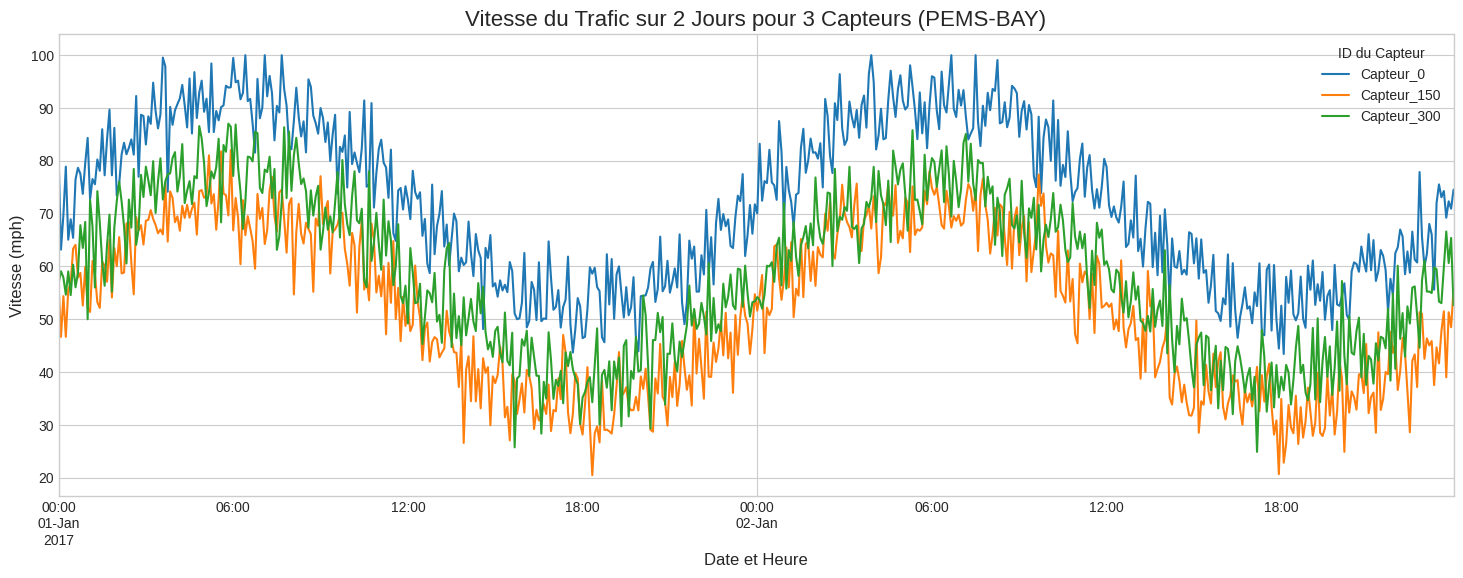

-> On observe clairement les cycles journaliers avec des baisses de vitesse durant les heures de pointe (matin et soir).

VISUALISATION DES PATRONS SPATIO-TEMPORELS (HEATMAP)


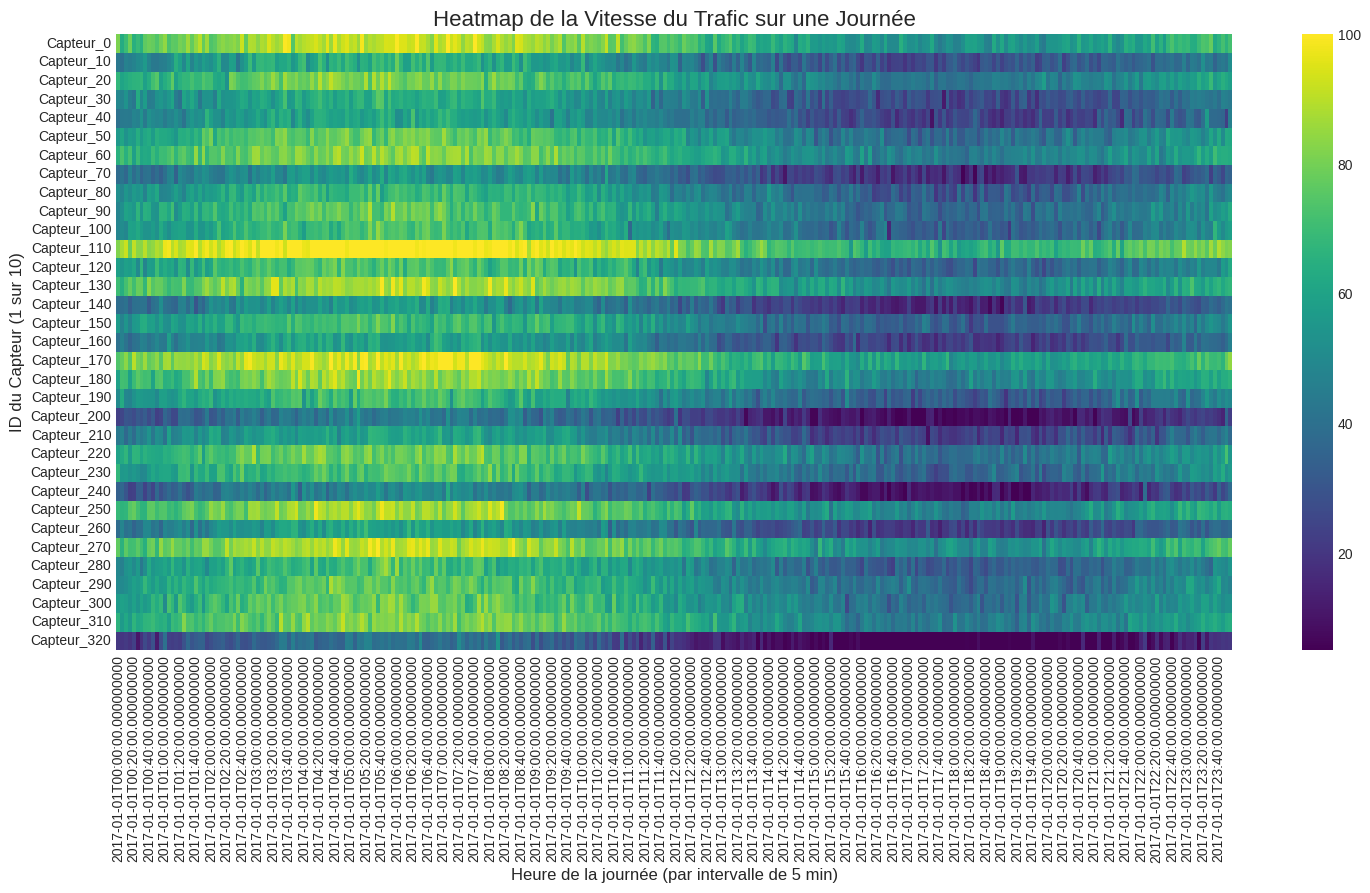

-> La heatmap montre comment la congestion (couleurs sombres, ex: jaune/vert) se propage à travers le temps et l'espace.

VISUALISATION DE LA STRUCTURE DU GRAPHE (MATRICE D'ADJACENCE)


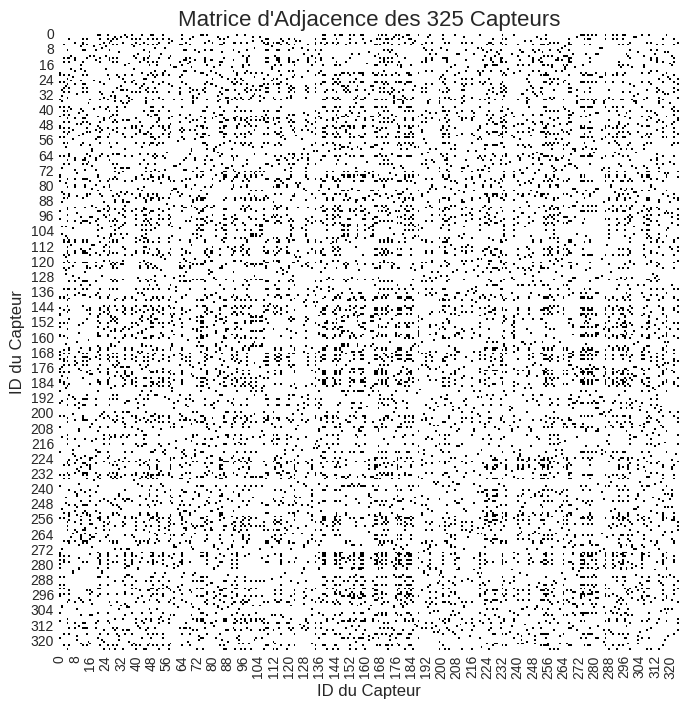

-> Chaque point représente une connexion (proximité) entre deux capteurs sur le réseau routier.

DISTRIBUTION GLOBALE DE LA VITESSE


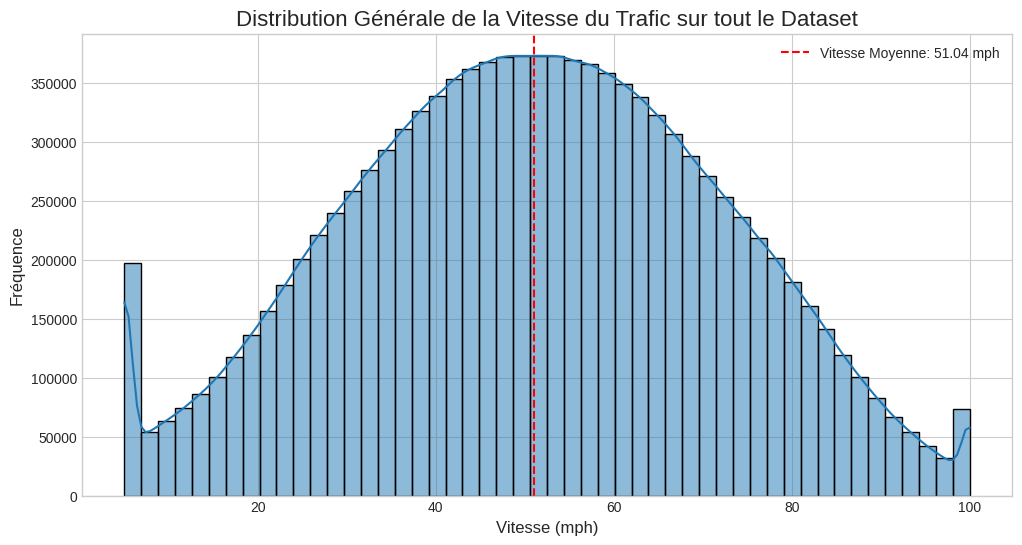

-> La vitesse est principalement concentrée autour de 50-70 mph, ce qui correspond à un trafic fluide à légèrement dense.

TENDANCE JOURNALIÈRE MOYENNE (AGRÉGÉE)


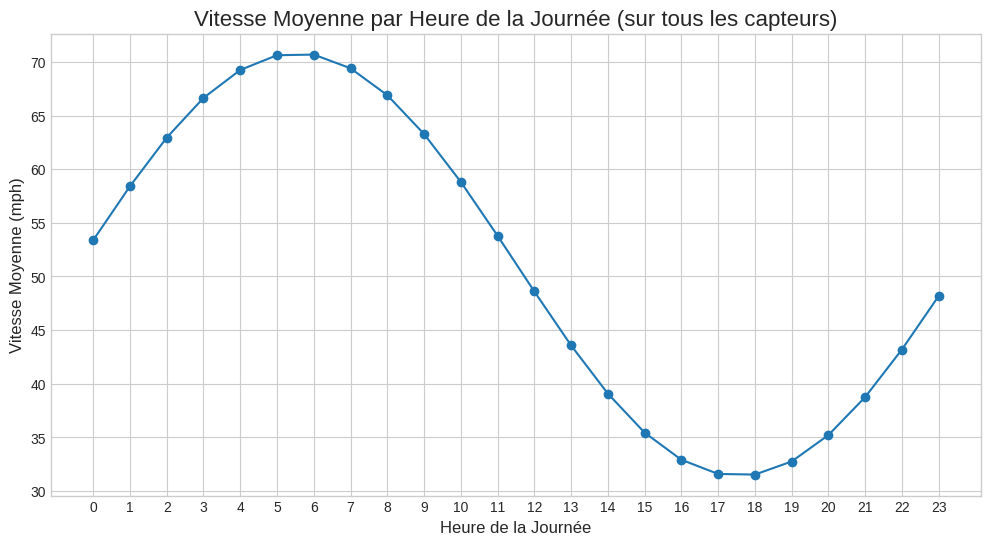

-> Ce graphique confirme les heures de pointe du matin (vers 8h) et du soir (vers 17-18h) avec des baisses de vitesse significatives.

TENDANCE HEBDOMADAIRE MOYENNE (AGRÉGÉE)


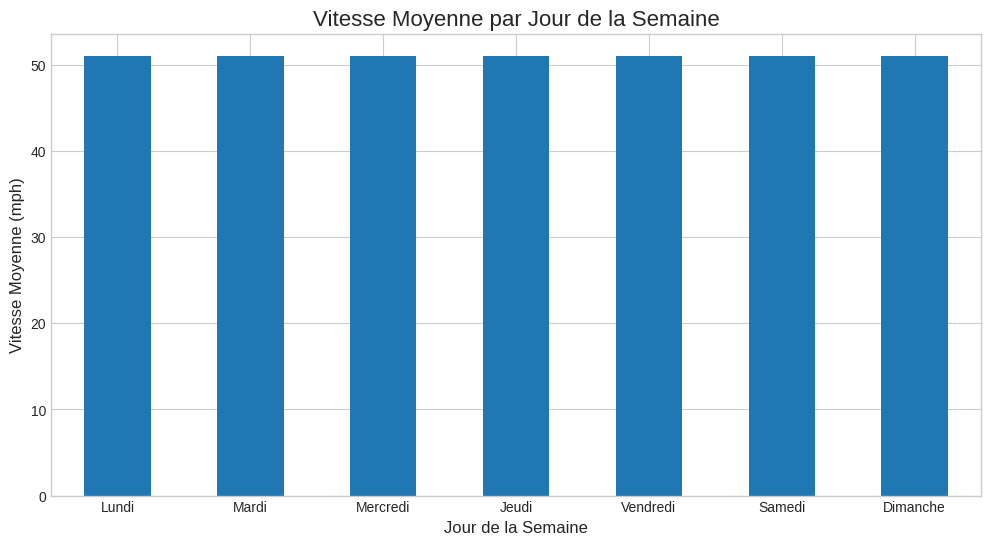

-> On voit clairement que le trafic est plus fluide (vitesse moyenne plus élevée) le week-end (Samedi, Dimanche).

DISTRIBUTION SPATIALE DES VITESSES


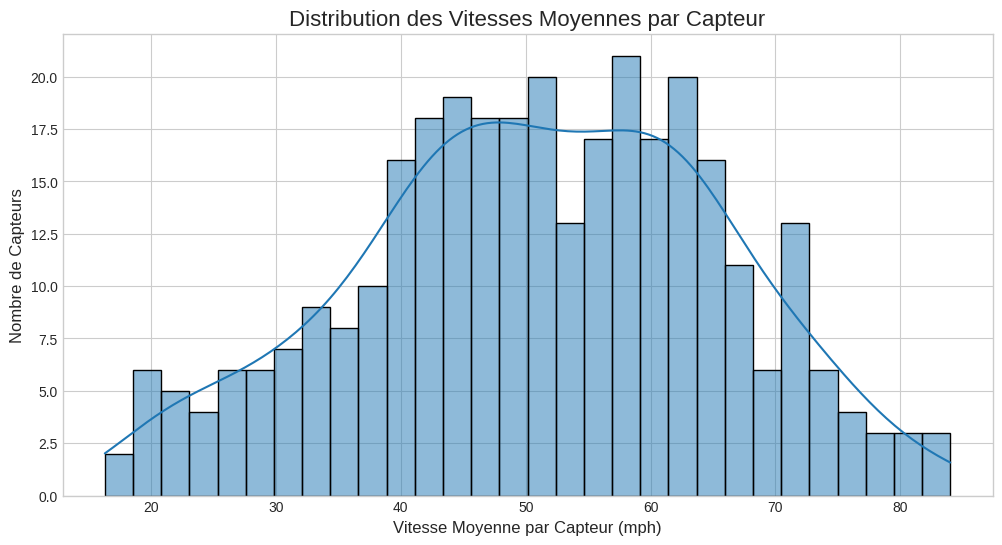

-> Ce graphique montre la variabilité spatiale. Certains capteurs sont situés dans des zones systématiquement plus lentes (congestion chronique) tandis que d'autres sont dans des zones plus rapides.


34059

In [8]:
# ============================================================================
# Code pour l'analyse et la visualisation des données PEMS-BAY (Version Complète)
# ============================================================================
from datetime import datetime, timedelta
# 1. Chargement des données à l'aide de notre DataLoader
print("Chargement des données pour l'analyse exploratoire...")
data_loader_eda = PEMSBAYDataLoader()
# Nous rechargeons les données pour cette section d'analyse uniquement.
traffic_data_np, adj_matrix_np = data_loader_eda.load_data()

# Création d'un DataFrame pandas pour une manipulation plus facile
# Note : Si les timestamps réels sont disponibles, ils seront utilisés comme index.
if hasattr(data_loader_eda, 'timestamps') and data_loader_eda.timestamps is not None:
    index = data_loader_eda.timestamps
else:
    # Création d'un index temporel de 5 minutes si les timestamps ne sont pas chargés
    start_time = datetime(2017, 1, 1)
    index = pd.to_datetime([start_time + timedelta(minutes=5*i) for i in range(len(traffic_data_np))])

df_traffic = pd.DataFrame(traffic_data_np, index=index, columns=[f'Capteur_{i}' for i in range(data_loader_eda.num_nodes)])


# 2. Afficher les champs et des exemples de données
print("\n" + "="*50)
print("APERÇU DES DONNÉES DE TRAFIC (5 PREMIÈRES LIGNES)")
print("="*50)
print(df_traffic.head())

print("\n" + "="*50)
print("INFORMATIONS SUR LA STRUCTURE DU DATAFRAME")
print("="*50)
df_traffic.info()

print("\n" + "="*50)
print("STATISTIQUES DESCRIPTIVES (VITESSE EN MPH)")
print("="*50)
print(df_traffic.describe())

# Utiliser un style de graphique cohérent pour toutes les visualisations
plt.style.use('seaborn-v0_8-whitegrid')


# 3. Visualisations - Graphiques Existants
# =========================================

# a) Visualisation Temporelle : Vitesse de quelques capteurs sur 2 jours
print("\n" + "="*50)
print("VISUALISATION DES PATRONS TEMPORELS (ÉCHANTILLON DE CAPTEURS)")
print("="*50)
fig, ax = plt.subplots(figsize=(18, 6))

capteurs_a_visualiser = ['Capteur_0', 'Capteur_150', 'Capteur_300']
df_traffic[capteurs_a_visualiser].iloc[:288*2].plot(ax=ax) # 288 mesures par jour (24h * 60min / 5min)

ax.set_title('Vitesse du Trafic sur 2 Jours pour 3 Capteurs (PEMS-BAY)', fontsize=16)
ax.set_xlabel('Date et Heure', fontsize=12)
ax.set_ylabel('Vitesse (mph)', fontsize=12)
ax.legend(title='ID du Capteur')
plt.show()
print("-> On observe clairement les cycles journaliers avec des baisses de vitesse durant les heures de pointe (matin et soir).")

# b) Visualisation Spatio-Temporelle : Heatmap du trafic sur une journée
print("\n" + "="*50)
print("VISUALISATION DES PATRONS SPATIO-TEMPORELS (HEATMAP)")
print("="*50)
fig, ax = plt.subplots(figsize=(18, 8))
sns.heatmap(df_traffic.iloc[:288, ::10].T, cmap='viridis', ax=ax)
ax.set_title('Heatmap de la Vitesse du Trafic sur une Journée', fontsize=16)
ax.set_xlabel('Heure de la journée (par intervalle de 5 min)', fontsize=12)
ax.set_ylabel('ID du Capteur (1 sur 10)', fontsize=12)
plt.show()
print("-> La heatmap montre comment la congestion (couleurs sombres, ex: jaune/vert) se propage à travers le temps et l'espace.")

# c) Visualisation de la Matrice d'Adjacence
print("\n" + "="*50)
print("VISUALISATION DE LA STRUCTURE DU GRAPHE (MATRICE D'ADJACENCE)")
print("="*50)
fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(adj_matrix_np, cmap='Greys', cbar=False, ax=ax)
ax.set_title("Matrice d'Adjacence des 325 Capteurs", fontsize=16)
ax.set_xlabel('ID du Capteur', fontsize=12)
ax.set_ylabel('ID du Capteur', fontsize=12)
plt.show()
print("-> Chaque point représente une connexion (proximité) entre deux capteurs sur le réseau routier.")


# 4. Visualisations - Nouveaux Graphiques
# =======================================

# d) Distribution Globale de la Vitesse du Trafic
print("\n" + "="*50)
print("DISTRIBUTION GLOBALE DE LA VITESSE")
print("="*50)
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(df_traffic.values.flatten(), bins=50, kde=True, ax=ax)
mean_speed = df_traffic.values.flatten().mean()
ax.axvline(mean_speed, color='red', linestyle='--', label=f'Vitesse Moyenne: {mean_speed:.2f} mph')
ax.set_title('Distribution Générale de la Vitesse du Trafic sur tout le Dataset', fontsize=16)
ax.set_xlabel('Vitesse (mph)', fontsize=12)
ax.set_ylabel('Fréquence', fontsize=12)
ax.legend()
plt.show()
print("-> La vitesse est principalement concentrée autour de 50-70 mph, ce qui correspond à un trafic fluide à légèrement dense.")

# e) Tendance Journalière Moyenne
print("\n" + "="*50)
print("TENDANCE JOURNALIÈRE MOYENNE (AGRÉGÉE)")
print("="*50)
fig, ax = plt.subplots(figsize=(12, 6))
df_traffic.groupby(df_traffic.index.hour).mean().mean(axis=1).plot(ax=ax, marker='o')
ax.set_title('Vitesse Moyenne par Heure de la Journée (sur tous les capteurs)', fontsize=16)
ax.set_xlabel('Heure de la Journée', fontsize=12)
ax.set_ylabel('Vitesse Moyenne (mph)', fontsize=12)
ax.set_xticks(range(24))
plt.show()
print("-> Ce graphique confirme les heures de pointe du matin (vers 8h) et du soir (vers 17-18h) avec des baisses de vitesse significatives.")

# f) Tendance Hebdomadaire Moyenne
print("\n" + "="*50)
print("TENDANCE HEBDOMADAIRE MOYENNE (AGRÉGÉE)")
print("="*50)
fig, ax = plt.subplots(figsize=(12, 6))
daily_avg = df_traffic.groupby(df_traffic.index.dayofweek).mean().mean(axis=1)
day_names = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']
daily_avg.index = day_names
daily_avg.plot(kind='bar', ax=ax, rot=0)
ax.set_title('Vitesse Moyenne par Jour de la Semaine', fontsize=16)
ax.set_xlabel('Jour de la Semaine', fontsize=12)
ax.set_ylabel('Vitesse Moyenne (mph)', fontsize=12)
plt.show()
print("-> On voit clairement que le trafic est plus fluide (vitesse moyenne plus élevée) le week-end (Samedi, Dimanche).")


# g) Distribution des Vitesses Moyennes par Capteur
print("\n" + "="*50)
print("DISTRIBUTION SPATIALE DES VITESSES")
print("="*50)
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(df_traffic.mean(axis=0), bins=30, kde=True, ax=ax)
ax.set_title('Distribution des Vitesses Moyennes par Capteur', fontsize=16)
ax.set_xlabel('Vitesse Moyenne par Capteur (mph)', fontsize=12)
ax.set_ylabel('Nombre de Capteurs', fontsize=12)
plt.show()
print("-> Ce graphique montre la variabilité spatiale. Certains capteurs sont situés dans des zones systématiquement plus lentes (congestion chronique) tandis que d'autres sont dans des zones plus rapides.")

# Supprimer les variables pour libérer la mémoire avant l'entraînement des modèles
del data_loader_eda, traffic_data_np, adj_matrix_np, df_traffic
import gc
gc.collect()

## 🧠 Section 4 — Définition des modèles

In [10]:
# =============================================================================
# SECTION 4: MODÈLES ADAPTÉS POUR PEMS-BAY
# =============================================================================
print("=" * 80)
print("🔴 SECTION 4: DÉFINITION DES MODÈLES")
print("=" * 80)

# ─── GraphConvBlock (partagé) ────────────────────────────────────────────────
class GraphConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.2):
        super().__init__()
        self.gcn1     = GCNConv(in_ch, out_ch)
        self.gcn2     = GCNConv(out_ch, out_ch)
        self.dropout  = nn.Dropout(dropout)
        self.relu     = nn.ReLU()
        self.residual = nn.Linear(in_ch, out_ch) if in_ch != out_ch else nn.Identity()

    def forward(self, x, edge_index, edge_weight=None):
        res = self.residual(x)
        x   = self.relu(self.gcn1(x, edge_index, edge_weight))
        x   = self.dropout(x)
        x   = self.gcn2(x, edge_index, edge_weight)
        return self.relu(x + res)


# ─── Modèle 1 : LSTM + Attention ─────────────────────────────────────────────
class LSTMModel_PEMSBAY(nn.Module):
    """LSTM bidirectionnel avec attention pour PEMS-BAY."""

    def __init__(self, input_dim=325, hidden_dim=64, num_layers=2,
                 seq_len=12, pred_len=3, dropout=0.2):
        super().__init__()
        self.input_dim  = input_dim
        self.hidden_dim = hidden_dim
        self.seq_len    = seq_len
        self.pred_len   = pred_len

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0,
                            bidirectional=True)
        self.attention = nn.MultiheadAttention(hidden_dim * 2, num_heads=8, dropout=dropout)
        self.dropout   = nn.Dropout(dropout)
        self.fc1       = nn.Linear(hidden_dim * 2, hidden_dim)
        self.fc2       = nn.Linear(hidden_dim, input_dim * pred_len)
        self.relu      = nn.ReLU()

    def forward(self, x, edge_index=None, edge_weight=None):
        B = x.size(0)
        lstm_out, _ = self.lstm(x)
        q = lstm_out.permute(1, 0, 2)
        attn_out, _ = self.attention(q, q, q)
        out = attn_out.permute(1, 0, 2)[:, -1, :]
        out = self.dropout(self.relu(self.fc1(out)))
        out = self.fc2(self.dropout(out))
        return out.view(B, self.pred_len, self.input_dim)


# ─── Modèle 2 : GNN ──────────────────────────────────────────────────────────
class GNNModel_PEMSBAY(nn.Module):
    """GNN (encodeur LSTM + GCN) pour PEMS-BAY."""

    def __init__(self, input_dim=1, hidden_dim=64, num_nodes=325,
                 num_gcn_blocks=4, seq_len=12, pred_len=3, dropout=0.2):
        super().__init__()
        self.num_nodes = num_nodes
        self.seq_len   = seq_len
        self.pred_len  = pred_len

        self.temporal_encoder = nn.LSTM(input_dim, hidden_dim, num_layers=2,
                                         batch_first=True, dropout=dropout)
        self.gcn_blocks = nn.ModuleList([
            GraphConvBlock(hidden_dim, hidden_dim, dropout) for _ in range(num_gcn_blocks)
        ])
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, pred_len)
        )

    def forward(self, x, edge_index, edge_weight=None):
        B = x.size(0)
        # x : (B, seq_len, num_nodes)
        x = x.permute(0, 2, 1).contiguous().view(B * self.num_nodes, self.seq_len, 1)
        enc, _ = self.temporal_encoder(x)
        x = enc[:, -1, :].view(B, self.num_nodes, -1)
        outputs = []
        for i in range(B):
            nf = x[i]
            for blk in self.gcn_blocks:
                nf = blk(nf, edge_index, edge_weight)
            outputs.append(self.decoder(nf))           # (num_nodes, pred_len)
        out = torch.stack(outputs, dim=0)               # (B, num_nodes, pred_len)
        return out.permute(0, 2, 1)                     # (B, pred_len, num_nodes)


# ─── Modèle 3 : ST-GNN ───────────────────────────────────────────────────────
class STGNN_PEMSBAY(nn.Module):
    """Spatio-Temporal GNN pour PEMS-BAY."""

    def __init__(self, num_nodes=325, input_dim=1, hidden_dim=64,
                 num_st_blocks=3, seq_len=12, pred_len=3, dropout=0.2):
        super().__init__()
        self.num_nodes = num_nodes
        self.seq_len   = seq_len
        self.pred_len  = pred_len

        self.input_proj = nn.Linear(input_dim, hidden_dim)
        self.temp_convs = nn.ModuleList([
            nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3, padding=1)
            for _ in range(num_st_blocks)
        ])
        self.graph_convs = nn.ModuleList([
            GCNConv(hidden_dim, hidden_dim) for _ in range(num_st_blocks)
        ])
        self.fusion_layers = nn.ModuleList([
            nn.Linear(hidden_dim * 2, hidden_dim) for _ in range(num_st_blocks)
        ])
        self.output_proj = nn.Sequential(
            nn.Linear(seq_len * hidden_dim, hidden_dim * 2), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, pred_len)
        )
        self.dropout = nn.Dropout(dropout)
        self.relu    = nn.ReLU()

    def forward(self, x, edge_index, edge_weight=None):
        B = x.size(0)
        x = x.unsqueeze(-1)                              # (B, T, N, 1)
        x = self.input_proj(x)                           # (B, T, N, H)

        for i in range(len(self.temp_convs)):
            # Temporal
            xt = x.permute(0, 2, 3, 1).contiguous().view(B * self.num_nodes, -1, self.seq_len)
            xt = self.relu(self.temp_convs[i](xt))
            xt = self.dropout(xt)
            xt = xt.view(B, self.num_nodes, -1, self.seq_len).permute(0, 3, 1, 2)

            # Spatial
            xs_list = []
            for t in range(self.seq_len):
                nf = x[:, t, :, :]
                b_out = torch.stack([self.graph_convs[i](nf[b], edge_index, edge_weight)
                                     for b in range(B)], dim=0)
                xs_list.append(b_out)
            xs = torch.stack(xs_list, dim=1)             # (B, T, N, H)

            x = self.relu(self.fusion_layers[i](torch.cat([xt, xs], dim=-1)))

        x = x.permute(0, 2, 1, 3).contiguous().view(B, self.num_nodes, -1)
        out = self.output_proj(x)                        # (B, N, pred_len)
        return out.permute(0, 2, 1)                      # (B, pred_len, N)


# ─── Modèle 4 : Hybrid LSTM-GNN ──────────────────────────────────────────────
class HybridLSTMGNN_PEMSBAY(nn.Module):
    """Hybride GCN + GRU bidirectionnel + attention pour PEMS-BAY."""

    def __init__(self, num_nodes=325, input_dim=1, hidden_dim=64,
                 num_gcn_layers=3, seq_len=12, pred_len=3, dropout=0.2):
        super().__init__()
        self.num_nodes = num_nodes
        self.seq_len   = seq_len
        self.pred_len  = pred_len
        self.hidden_dim = hidden_dim

        self.spatial_encoder = nn.ModuleList([
            GCNConv(input_dim if i == 0 else hidden_dim, hidden_dim)
            for i in range(num_gcn_layers)
        ])
        self.temporal_encoder = nn.GRU(
            input_size=hidden_dim, hidden_size=hidden_dim, num_layers=2,
            batch_first=True, bidirectional=True, dropout=dropout
        )
        self.attention = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, 1, bias=False)
        )
        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, pred_len)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index, edge_weight=None):
        B = x.size(0)
        # x : (B, T, N) -> reshape to (B*T, N, 1)
        xt = x.view(B * self.seq_len, self.num_nodes, 1)
        sf = xt
        for gcn in self.spatial_encoder:
            sf = F.relu(gcn(sf, edge_index, edge_weight))
            sf = self.dropout(sf)
        # sf : (B*T, N, H) -> (B, N, T, H)
        sf = sf.view(B, self.seq_len, self.num_nodes, -1)
        sf = sf.permute(0, 2, 1, 3).contiguous().view(B * self.num_nodes, self.seq_len, -1)
        temp_out, _ = self.temporal_encoder(sf)
        attn_w = F.softmax(self.attention(temp_out), dim=1)
        attended = (temp_out * attn_w).sum(dim=1)
        preds = self.output_layer(attended)              # (B*N, pred_len)
        preds = preds.view(B, self.num_nodes, self.pred_len)
        return preds.permute(0, 2, 1)                   # (B, pred_len, N)


print("✅ 4 modèles définis : LSTM, GNN, ST-GNN, Hybrid LSTM-GNN")

🔴 SECTION 4: DÉFINITION DES MODÈLES
✅ 4 modèles définis : LSTM, GNN, ST-GNN, Hybrid LSTM-GNN


## ⚙️ Section 5 — Métriques & Fonctions d'entraînement

In [21]:
# =============================================================================
# SECTION 5: MÉTRIQUES & ENTRAÎNEMENT
# =============================================================================
print("=" * 80)
print("🔴 SECTION 5: MÉTRIQUES & ENTRAÎNEMENT")
print("=" * 80)

def calculate_metrics(predictions, targets, threshold=1.0):
    """Calcule MAE, RMSE, MAPE (numpy arrays)."""
    mae  = np.mean(np.abs(predictions - targets))
    rmse = np.sqrt(np.mean((predictions - targets) ** 2))
    mask = np.abs(targets) > threshold
    mape = np.mean(np.abs((targets[mask] - predictions[mask]) / targets[mask])) * 100 if mask.sum() > 0 else 0.0
    return mae, rmse, mape


def model_uses_graph(model):
    """Vérifie si le modèle nécessite edge_index."""
    return not isinstance(model, LSTMModel_PEMSBAY)


def train_epoch(model, loader, optimizer, criterion, max_batches=None):
    model.train()
    total_loss = 0
    use_amp = config.DEVICE == 'cuda'
    scaler  = torch.cuda.amp.GradScaler(enabled=use_amp)
    limit   = min(len(loader), max_batches) if max_batches else len(loader)
    iterator = loader if max_batches is None else itertools.islice(loader, limit)

    for batch in iterator:
        x = batch['x'].to(config.DEVICE)
        y = batch['y'].to(config.DEVICE)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=use_amp):
            if model_uses_graph(model):
                pred = model(x, edge_index, edge_weight)
            else:
                pred = model(x)
            loss = criterion(pred, y)

        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            clip_grad_norm_(model.parameters(), config.GRADIENT_CLIP_VALUE)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            clip_grad_norm_(model.parameters(), config.GRADIENT_CLIP_VALUE)
            optimizer.step()

        total_loss += loss.item()

    return total_loss / max(1, limit)


def evaluate_model(model, loader, criterion, max_batches=None):
    model.eval()
    total_loss = 0
    all_preds, all_targets = [], []
    limit    = min(len(loader), max_batches) if max_batches else len(loader)
    iterator = loader if max_batches is None else itertools.islice(loader, limit)
    use_amp  = config.DEVICE == 'cuda'

    with torch.no_grad():
        for batch in iterator:
            x = batch['x'].to(config.DEVICE)
            y = batch['y'].to(config.DEVICE)
            with torch.cuda.amp.autocast(enabled=use_amp):
                if model_uses_graph(model):
                    pred = model(x, edge_index, edge_weight)
                else:
                    pred = model(x)
                loss = criterion(pred, y)
            total_loss += loss.item()
            all_preds.append(pred.cpu().numpy())
            all_targets.append(y.cpu().numpy())

    preds   = np.concatenate(all_preds, axis=0)
    targets = np.concatenate(all_targets, axis=0)
    preds_d   = data_loader.denormalize(preds)
    targets_d = data_loader.denormalize(targets)
    mae, rmse, mape = calculate_metrics(preds_d, targets_d)

    return {
        'loss': total_loss / max(1, limit),
        'mae': mae, 'rmse': rmse, 'mape': mape
    }, preds_d, targets_d


def full_train(model, epochs, batch_size, lr, save_path):
    """Entraîne un modèle jusqu'à convergence (early stopping)."""
    tr_loader, va_loader, _ = build_loaders(batch_size)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=config.WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.L1Loss()

    best_mae     = float('inf')
    patience_ctr = 0
    history      = {'train_loss': [], 'val_mae': []}

    for epoch in range(1, epochs + 1):
        tr_loss = train_epoch(model, tr_loader, optimizer, criterion)
        val_met, _, _ = evaluate_model(model, va_loader, criterion)
        scheduler.step()

        history['train_loss'].append(tr_loss)
        history['val_mae'].append(val_met['mae'])

        print(f"Epoch {epoch:3d}/{epochs} | Train Loss: {tr_loss:.4f} | "
              f"Val MAE: {val_met['mae']:.4f} mph | RMSE: {val_met['rmse']:.4f} | MAPE: {val_met['mape']:.2f}%")

        if val_met['mae'] < best_mae:
            best_mae     = val_met['mae']
            patience_ctr = 0
            torch.save({'model_state': model.state_dict(), 'epoch': epoch,
                        'best_mae': best_mae}, save_path)
            print(f"  ✓ Nouveau meilleur modèle! MAE={best_mae:.4f}")
        else:
            patience_ctr += 1
            if patience_ctr >= config.EARLY_STOPPING_PATIENCE:
                print(f"  Early stopping à l'époque {epoch}")
                break

    ckpt = torch.load(save_path, map_location=config.DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state'])
    return model, history

print("✅ Fonctions d'entraînement prêtes")

🔴 SECTION 5: MÉTRIQUES & ENTRAÎNEMENT
✅ Fonctions d'entraînement prêtes


## 🔬 Section 6 — Optimisation des hyperparamètres (Optuna)

In [24]:
# =============================================================================
# SECTION 6: OPTIMISATION DES HYPERPARAMÈTRES (OPTUNA)
# =============================================================================
print("=" * 80)
print("🔴 SECTION 6: OPTIMISATION HP (Optuna)")
print("=" * 80)

# ──── Dictionnaire global des meilleurs hyperparamètres ──────────────────────
best_hyperparams = {}

# ──────────────────────────────────────────────────────────────────────────────
# 6.1 — OPTUNA pour LSTM
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "─"*60)
print("🔷 6.1 Optimisation LSTM")
print("─"*60)

def objective_lstm(trial):
    hidden_dim  = trial.suggest_categorical('hidden_dim',  [32, 64, 128])
    num_layers  = trial.suggest_int('num_layers', 1, 3)
    dropout     = trial.suggest_float('dropout', 0.0, 0.4, step=0.1)
    lr          = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    batch_size  = trial.suggest_categorical('batch_size', [16, 32, 64])

    model = LSTMModel_PEMSBAY(
        input_dim=config.NUM_NODES, hidden_dim=hidden_dim,
        num_layers=num_layers, seq_len=config.SEQ_LEN,
        pred_len=config.PRED_LEN, dropout=dropout
    ).to(config.DEVICE)

    tr_loader, va_loader, _ = build_loaders(batch_size)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=config.WEIGHT_DECAY)
    criterion = nn.L1Loss()

    n_epochs   = config.OPTUNA_FAST_EPOCHS if config.OPTUNA_FAST else 10
    max_train  = config.OPTUNA_FAST_MAX_TRAIN_B if config.OPTUNA_FAST else None
    max_val    = config.OPTUNA_FAST_MAX_VAL_B   if config.OPTUNA_FAST else None

    best_val_mae = float('inf')
    for epoch in range(1, n_epochs + 1):
        train_epoch(model, tr_loader, optimizer, criterion, max_batches=max_train)
        val_met, _, _ = evaluate_model(model, va_loader, criterion, max_batches=max_val)
        best_val_mae = min(best_val_mae, val_met['mae'])
        trial.report(val_met['mae'], epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    del model
    torch.cuda.empty_cache() if config.DEVICE == 'cuda' else None
    return best_val_mae

study_lstm = optuna.create_study(
    direction='minimize', study_name='lstm_pems_bay',
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=config.OPTUNA_PRUNING_WARMUP)
)
study_lstm.optimize(objective_lstm, n_trials=config.OPTUNA_N_TRIALS, timeout=config.OPTUNA_TIMEOUT)
best_hyperparams['lstm'] = study_lstm.best_params
print(f"\n✅ Meilleurs HP LSTM : {best_hyperparams['lstm']}")

# ──────────────────────────────────────────────────────────────────────────────
# 6.2 — OPTUNA pour GNN
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "─"*60)
print("🔷 6.2 Optimisation GNN")
print("─"*60)

def objective_gnn(trial):
    hidden_dim    = trial.suggest_categorical('hidden_dim',    [32, 64, 128])
    num_gcn_blocks = trial.suggest_int('num_gcn_blocks', 2, 5)
    dropout       = trial.suggest_float('dropout', 0.0, 0.4, step=0.1)
    lr            = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    batch_size    = trial.suggest_categorical('batch_size', [16, 32])

    model = GNNModel_PEMSBAY(
        input_dim=1, hidden_dim=hidden_dim, num_nodes=config.NUM_NODES,
        num_gcn_blocks=num_gcn_blocks, seq_len=config.SEQ_LEN,
        pred_len=config.PRED_LEN, dropout=dropout
    ).to(config.DEVICE)

    tr_loader, va_loader, _ = build_loaders(batch_size)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=config.WEIGHT_DECAY)
    criterion = nn.L1Loss()

    n_epochs  = config.OPTUNA_FAST_EPOCHS if config.OPTUNA_FAST else 10
    max_train = config.OPTUNA_FAST_MAX_TRAIN_B if config.OPTUNA_FAST else None
    max_val   = config.OPTUNA_FAST_MAX_VAL_B   if config.OPTUNA_FAST else None

    best_val_mae = float('inf')
    for epoch in range(1, n_epochs + 1):
        train_epoch(model, tr_loader, optimizer, criterion, max_batches=max_train)
        val_met, _, _ = evaluate_model(model, va_loader, criterion, max_batches=max_val)
        best_val_mae = min(best_val_mae, val_met['mae'])
        trial.report(val_met['mae'], epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    del model
    torch.cuda.empty_cache() if config.DEVICE == 'cuda' else None
    return best_val_mae

study_gnn = optuna.create_study(
    direction='minimize', study_name='gnn_pems_bay',
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=config.OPTUNA_PRUNING_WARMUP)
)
study_gnn.optimize(objective_gnn, n_trials=config.OPTUNA_N_TRIALS, timeout=config.OPTUNA_TIMEOUT)
best_hyperparams['gnn'] = study_gnn.best_params
print(f"\n✅ Meilleurs HP GNN : {best_hyperparams['gnn']}")

# ──────────────────────────────────────────────────────────────────────────────
# 6.3 — OPTUNA pour ST-GNN
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "─"*60)
print("🔷 6.3 Optimisation ST-GNN")
print("─"*60)

def objective_stgnn(trial):
    hidden_dim   = trial.suggest_categorical('hidden_dim',   [32, 64, 128])
    num_st_blocks = trial.suggest_int('num_st_blocks', 2, 4)
    dropout      = trial.suggest_float('dropout', 0.0, 0.4, step=0.1)
    lr           = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    batch_size   = trial.suggest_categorical('batch_size', [8, 16])

    model = STGNN_PEMSBAY(
        num_nodes=config.NUM_NODES, input_dim=1, hidden_dim=hidden_dim,
        num_st_blocks=num_st_blocks, seq_len=config.SEQ_LEN,
        pred_len=config.PRED_LEN, dropout=dropout
    ).to(config.DEVICE)

    tr_loader, va_loader, _ = build_loaders(batch_size)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=config.WEIGHT_DECAY)
    criterion = nn.L1Loss()

    n_epochs  = config.OPTUNA_FAST_EPOCHS if config.OPTUNA_FAST else 10
    max_train = config.OPTUNA_FAST_MAX_TRAIN_B if config.OPTUNA_FAST else None
    max_val   = config.OPTUNA_FAST_MAX_VAL_B   if config.OPTUNA_FAST else None

    best_val_mae = float('inf')
    for epoch in range(1, n_epochs + 1):
        train_epoch(model, tr_loader, optimizer, criterion, max_batches=max_train)
        val_met, _, _ = evaluate_model(model, va_loader, criterion, max_batches=max_val)
        best_val_mae = min(best_val_mae, val_met['mae'])
        trial.report(val_met['mae'], epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    del model
    torch.cuda.empty_cache() if config.DEVICE == 'cuda' else None
    return best_val_mae

study_stgnn = optuna.create_study(
    direction='minimize', study_name='stgnn_pems_bay',
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=config.OPTUNA_PRUNING_WARMUP)
)
study_stgnn.optimize(objective_stgnn, n_trials=config.OPTUNA_N_TRIALS, timeout=config.OPTUNA_TIMEOUT)
best_hyperparams['stgnn'] = study_stgnn.best_params
print(f"\n✅ Meilleurs HP ST-GNN : {best_hyperparams['stgnn']}")

# ──────────────────────────────────────────────────────────────────────────────
# 6.4 — OPTUNA pour Hybrid LSTM-GNN
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "─"*60)
print("🔷 6.4 Optimisation Hybrid LSTM-GNN")
print("─"*60)

def objective_hybrid(trial):
    hidden_dim    = trial.suggest_categorical('hidden_dim',    [32, 64, 128])
    num_gcn_layers = trial.suggest_int('num_gcn_layers', 2, 4)
    dropout       = trial.suggest_float('dropout', 0.0, 0.4, step=0.1)
    lr            = trial.suggest_float('lr', 1e-4, 5e-3, log=True)
    batch_size    = trial.suggest_categorical('batch_size', [8, 16])

    model = HybridLSTMGNN_PEMSBAY(
        num_nodes=config.NUM_NODES, input_dim=1, hidden_dim=hidden_dim,
        num_gcn_layers=num_gcn_layers, seq_len=config.SEQ_LEN,
        pred_len=config.PRED_LEN, dropout=dropout
    ).to(config.DEVICE)

    tr_loader, va_loader, _ = build_loaders(batch_size)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=config.WEIGHT_DECAY)
    criterion = nn.L1Loss()

    n_epochs  = config.OPTUNA_FAST_EPOCHS if config.OPTUNA_FAST else 10
    max_train = config.OPTUNA_FAST_MAX_TRAIN_B if config.OPTUNA_FAST else None
    max_val   = config.OPTUNA_FAST_MAX_VAL_B   if config.OPTUNA_FAST else None

    best_val_mae = float('inf')
    for epoch in range(1, n_epochs + 1):
        train_epoch(model, tr_loader, optimizer, criterion, max_batches=max_train)
        val_met, _, _ = evaluate_model(model, va_loader, criterion, max_batches=max_val)
        best_val_mae = min(best_val_mae, val_met['mae'])
        trial.report(val_met['mae'], epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    del model
    torch.cuda.empty_cache() if config.DEVICE == 'cuda' else None
    return best_val_mae

study_hybrid = optuna.create_study(
    direction='minimize', study_name='hybrid_pems_bay',
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=config.OPTUNA_PRUNING_WARMUP)
)
study_hybrid.optimize(objective_hybrid, n_trials=config.OPTUNA_N_TRIALS, timeout=config.OPTUNA_TIMEOUT)
best_hyperparams['hybrid'] = study_hybrid.best_params
print(f"\n✅ Meilleurs HP Hybrid : {best_hyperparams['hybrid']}")

# ── Sauvegarde JSON ──────────────────────────────────────────────────────────
hp_save_path = os.path.join(config.RESULTS_DIR, 'best_hyperparameters.json')
with open(hp_save_path, 'w') as f:
    json.dump(best_hyperparams, f, indent=4)
print(f"\n💾 Hyperparamètres sauvegardés → {hp_save_path}")
print("\n" + "="*80)
print("📊 RÉCAPITULATIF DES MEILLEURS HYPERPARAMÈTRES")
print("=" * 80)
for model_name, hp in best_hyperparams.items():
    print(f"\n🔹 {model_name.upper()}: {hp}")

[I 2026-04-12 00:54:17,662] A new study created in memory with name: lstm_pems_bay


🔴 SECTION 6: OPTIMISATION HP (Optuna)

────────────────────────────────────────────────────────────
🔷 6.1 Optimisation LSTM
────────────────────────────────────────────────────────────


[I 2026-04-12 00:54:24,997] Trial 0 finished with value: 4.176451206207275 and parameters: {'hidden_dim': 64, 'num_layers': 3, 'dropout': 0.1, 'lr': 0.0001531469376995079, 'batch_size': 16}. Best is trial 0 with value: 4.176451206207275.
[I 2026-04-12 00:54:30,194] Trial 1 finished with value: 3.9808218479156494 and parameters: {'hidden_dim': 32, 'num_layers': 1, 'dropout': 0.0, 'lr': 0.0007180650949286581, 'batch_size': 16}. Best is trial 1 with value: 3.9808218479156494.
[I 2026-04-12 00:54:35,523] Trial 2 finished with value: 4.335418224334717 and parameters: {'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.2, 'lr': 0.00023394061741426866, 'batch_size': 16}. Best is trial 1 with value: 3.9808218479156494.
[I 2026-04-12 00:54:40,698] Trial 3 pruned. 
[I 2026-04-12 00:54:43,964] Trial 4 pruned. 
[I 2026-04-12 00:54:53,032] Trial 5 finished with value: 4.035301685333252 and parameters: {'hidden_dim': 64, 'num_layers': 3, 'dropout': 0.1, 'lr': 0.0004972741263471962, 'batch_size': 32}. B


✅ Meilleurs HP LSTM : {'hidden_dim': 64, 'num_layers': 2, 'dropout': 0.0, 'lr': 0.0001244170892317615, 'batch_size': 32}

────────────────────────────────────────────────────────────
🔷 6.2 Optimisation GNN
────────────────────────────────────────────────────────────


[I 2026-04-12 00:57:52,749] Trial 0 finished with value: 4.1176228523254395 and parameters: {'hidden_dim': 32, 'num_gcn_blocks': 4, 'dropout': 0.1, 'lr': 0.0038456222155661365, 'batch_size': 16}. Best is trial 0 with value: 4.1176228523254395.
[I 2026-04-12 01:00:19,566] Trial 1 finished with value: 4.620122909545898 and parameters: {'hidden_dim': 32, 'num_gcn_blocks': 4, 'dropout': 0.0, 'lr': 0.0002719171371341428, 'batch_size': 16}. Best is trial 0 with value: 4.1176228523254395.
[I 2026-04-12 01:06:36,824] Trial 2 finished with value: 4.091017246246338 and parameters: {'hidden_dim': 128, 'num_gcn_blocks': 5, 'dropout': 0.30000000000000004, 'lr': 0.0009183401201025233, 'batch_size': 32}. Best is trial 2 with value: 4.091017246246338.
[I 2026-04-12 01:07:25,870] Trial 3 pruned. 
[I 2026-04-12 01:08:56,382] Trial 4 pruned. 
[I 2026-04-12 01:10:26,156] Trial 5 pruned. 
[I 2026-04-12 01:11:35,060] Trial 6 pruned. 
[I 2026-04-12 01:12:23,422] Trial 7 pruned. 
[I 2026-04-12 01:14:13,882] T


✅ Meilleurs HP GNN : {'hidden_dim': 128, 'num_gcn_blocks': 5, 'dropout': 0.30000000000000004, 'lr': 0.0009183401201025233, 'batch_size': 32}

────────────────────────────────────────────────────────────
🔷 6.3 Optimisation ST-GNN
────────────────────────────────────────────────────────────


[I 2026-04-12 01:22:58,365] Trial 0 finished with value: 4.914796352386475 and parameters: {'hidden_dim': 64, 'num_st_blocks': 2, 'dropout': 0.4, 'lr': 0.00022661570047524137, 'batch_size': 16}. Best is trial 0 with value: 4.914796352386475.
[I 2026-04-12 01:26:21,536] Trial 1 finished with value: 4.515133857727051 and parameters: {'hidden_dim': 64, 'num_st_blocks': 2, 'dropout': 0.2, 'lr': 0.004986545277840537, 'batch_size': 8}. Best is trial 1 with value: 4.515133857727051.
[I 2026-04-12 01:33:08,484] Trial 2 finished with value: 5.2000226974487305 and parameters: {'hidden_dim': 32, 'num_st_blocks': 4, 'dropout': 0.30000000000000004, 'lr': 0.003135089878853903, 'batch_size': 8}. Best is trial 1 with value: 4.515133857727051.
[I 2026-04-12 01:36:35,179] Trial 3 finished with value: 4.27057409286499 and parameters: {'hidden_dim': 128, 'num_st_blocks': 2, 'dropout': 0.0, 'lr': 0.0034579067576484784, 'batch_size': 8}. Best is trial 3 with value: 4.27057409286499.
[I 2026-04-12 01:40:02,6


✅ Meilleurs HP ST-GNN : {'hidden_dim': 128, 'num_st_blocks': 2, 'dropout': 0.0, 'lr': 0.003534030326898368, 'batch_size': 8}

────────────────────────────────────────────────────────────
🔷 6.4 Optimisation Hybrid LSTM-GNN
────────────────────────────────────────────────────────────


[I 2026-04-12 02:10:59,042] Trial 0 finished with value: 12.331828117370605 and parameters: {'hidden_dim': 32, 'num_gcn_layers': 2, 'dropout': 0.2, 'lr': 0.0006346656707472721, 'batch_size': 16}. Best is trial 0 with value: 12.331828117370605.
[I 2026-04-12 02:11:44,336] Trial 1 finished with value: 12.506832122802734 and parameters: {'hidden_dim': 64, 'num_gcn_layers': 4, 'dropout': 0.4, 'lr': 0.0044983841168529295, 'batch_size': 8}. Best is trial 0 with value: 12.331828117370605.
[I 2026-04-12 02:14:33,890] Trial 2 finished with value: 12.480242729187012 and parameters: {'hidden_dim': 128, 'num_gcn_layers': 4, 'dropout': 0.4, 'lr': 0.0008140943886257312, 'batch_size': 16}. Best is trial 0 with value: 12.331828117370605.
[I 2026-04-12 02:14:48,728] Trial 3 pruned. 
[I 2026-04-12 02:15:03,395] Trial 4 finished with value: 12.352424621582031 and parameters: {'hidden_dim': 32, 'num_gcn_layers': 2, 'dropout': 0.2, 'lr': 0.00036588282950483737, 'batch_size': 8}. Best is trial 0 with value:


✅ Meilleurs HP Hybrid : {'hidden_dim': 128, 'num_gcn_layers': 2, 'dropout': 0.4, 'lr': 0.0013774136122508968, 'batch_size': 16}

💾 Hyperparamètres sauvegardés → /kaggle/working/results/best_hyperparameters.json

📊 RÉCAPITULATIF DES MEILLEURS HYPERPARAMÈTRES

🔹 LSTM: {'hidden_dim': 64, 'num_layers': 2, 'dropout': 0.0, 'lr': 0.0001244170892317615, 'batch_size': 32}

🔹 GNN: {'hidden_dim': 128, 'num_gcn_blocks': 5, 'dropout': 0.30000000000000004, 'lr': 0.0009183401201025233, 'batch_size': 32}

🔹 STGNN: {'hidden_dim': 128, 'num_st_blocks': 2, 'dropout': 0.0, 'lr': 0.003534030326898368, 'batch_size': 8}

🔹 HYBRID: {'hidden_dim': 128, 'num_gcn_layers': 2, 'dropout': 0.4, 'lr': 0.0013774136122508968, 'batch_size': 16}


## 🚀 Section 7 — Entraînement final avec les meilleurs hyperparamètres

In [25]:
# =============================================================================
# SECTION 7: ENTRAÎNEMENT FINAL
# =============================================================================
print("=" * 80)
print("🔴 SECTION 7: ENTRAÎNEMENT FINAL")
print("=" * 80)

final_results = {}
trained_models = {}

# ──────────────────────────────────────────────────────────────────────────────
# 7.1 — Entraînement final LSTM
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("🔶 7.1 Entraînement final LSTM")
print("="*60)

hp = best_hyperparams['lstm']
lstm_final = LSTMModel_PEMSBAY(
    input_dim=config.NUM_NODES,
    hidden_dim=hp['hidden_dim'],
    num_layers=hp['num_layers'],
    seq_len=config.SEQ_LEN,
    pred_len=config.PRED_LEN,
    dropout=hp['dropout']
).to(config.DEVICE)

n_params = sum(p.numel() for p in lstm_final.parameters())
print(f"Paramètres : {n_params:,}")
print(f"HP : {hp}")

lstm_final, hist_lstm = full_train(
    lstm_final, config.MAX_EPOCHS,
    batch_size=hp['batch_size'], lr=hp['lr'],
    save_path=os.path.join(config.RESULTS_DIR, 'best_lstm.pth')
)
trained_models['lstm'] = lstm_final

# ──────────────────────────────────────────────────────────────────────────────
# 7.2 — Entraînement final GNN
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("🔶 7.2 Entraînement final GNN")
print("="*60)

hp = best_hyperparams['gnn']
gnn_final = GNNModel_PEMSBAY(
    input_dim=1,
    hidden_dim=hp['hidden_dim'],
    num_nodes=config.NUM_NODES,
    num_gcn_blocks=hp['num_gcn_blocks'],
    seq_len=config.SEQ_LEN,
    pred_len=config.PRED_LEN,
    dropout=hp['dropout']
).to(config.DEVICE)

n_params = sum(p.numel() for p in gnn_final.parameters())
print(f"Paramètres : {n_params:,}")
print(f"HP : {hp}")

gnn_final, hist_gnn = full_train(
    gnn_final, config.MAX_EPOCHS,
    batch_size=hp['batch_size'], lr=hp['lr'],
    save_path=os.path.join(config.RESULTS_DIR, 'best_gnn.pth')
)
trained_models['gnn'] = gnn_final

# ──────────────────────────────────────────────────────────────────────────────
# 7.3 — Entraînement final ST-GNN
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("🔶 7.3 Entraînement final ST-GNN")
print("="*60)

hp = best_hyperparams['stgnn']
stgnn_final = STGNN_PEMSBAY(
    num_nodes=config.NUM_NODES,
    input_dim=1,
    hidden_dim=hp['hidden_dim'],
    num_st_blocks=hp['num_st_blocks'],
    seq_len=config.SEQ_LEN,
    pred_len=config.PRED_LEN,
    dropout=hp['dropout']
).to(config.DEVICE)

n_params = sum(p.numel() for p in stgnn_final.parameters())
print(f"Paramètres : {n_params:,}")
print(f"HP : {hp}")

stgnn_final, hist_stgnn = full_train(
    stgnn_final, config.MAX_EPOCHS,
    batch_size=hp['batch_size'], lr=hp['lr'],
    save_path=os.path.join(config.RESULTS_DIR, 'best_stgnn.pth')
)
trained_models['stgnn'] = stgnn_final

# ──────────────────────────────────────────────────────────────────────────────
# 7.4 — Entraînement final Hybrid LSTM-GNN
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("🔶 7.4 Entraînement final Hybrid LSTM-GNN")
print("="*60)

hp = best_hyperparams['hybrid']
hybrid_final = HybridLSTMGNN_PEMSBAY(
    num_nodes=config.NUM_NODES,
    input_dim=1,
    hidden_dim=hp['hidden_dim'],
    num_gcn_layers=hp['num_gcn_layers'],
    seq_len=config.SEQ_LEN,
    pred_len=config.PRED_LEN,
    dropout=hp['dropout']
).to(config.DEVICE)

n_params = sum(p.numel() for p in hybrid_final.parameters())
print(f"Paramètres : {n_params:,}")
print(f"HP : {hp}")

hybrid_final, hist_hybrid = full_train(
    hybrid_final, config.MAX_EPOCHS,
    batch_size=hp['batch_size'], lr=hp['lr'],
    save_path=os.path.join(config.RESULTS_DIR, 'best_hybrid.pth')
)
trained_models['hybrid'] = hybrid_final

print("\n✅ Tous les modèles entraînés avec les meilleurs hyperparamètres Optuna!")

🔴 SECTION 7: ENTRAÎNEMENT FINAL

🔶 7.1 Entraînement final LSTM
Paramètres : 437,199
HP : {'hidden_dim': 64, 'num_layers': 2, 'dropout': 0.0, 'lr': 0.0001244170892317615, 'batch_size': 32}
Epoch   1/10 | Train Loss: 0.2773 | Val MAE: 3.9576 mph | RMSE: 4.9855 | MAPE: 10.52%
  ✓ Nouveau meilleur modèle! MAE=3.9576
Epoch   2/10 | Train Loss: 0.1861 | Val MAE: 3.9485 mph | RMSE: 4.9757 | MAPE: 10.47%
  ✓ Nouveau meilleur modèle! MAE=3.9485
Epoch   3/10 | Train Loss: 0.1858 | Val MAE: 3.9431 mph | RMSE: 4.9676 | MAPE: 10.59%
  ✓ Nouveau meilleur modèle! MAE=3.9431
Epoch   4/10 | Train Loss: 0.1857 | Val MAE: 3.9347 mph | RMSE: 4.9604 | MAPE: 10.51%
  ✓ Nouveau meilleur modèle! MAE=3.9347
Epoch   5/10 | Train Loss: 0.1855 | Val MAE: 3.9341 mph | RMSE: 4.9591 | MAPE: 10.53%
  ✓ Nouveau meilleur modèle! MAE=3.9341
Epoch   6/10 | Train Loss: 0.1853 | Val MAE: 3.9289 mph | RMSE: 4.9532 | MAPE: 10.48%
  ✓ Nouveau meilleur modèle! MAE=3.9289
Epoch   7/10 | Train Loss: 0.1852 | Val MAE: 3.9278 mph 

## 📈 Section 8 — Évaluation finale sur le test set

In [26]:
# =============================================================================
# SECTION 8: ÉVALUATION FINALE (TEST SET)
# =============================================================================
print("=" * 80)
print("🔴 SECTION 8: ÉVALUATION FINALE SUR LE TEST SET")
print("=" * 80)

criterion = nn.L1Loss()
_, _, test_loader_final = build_loaders(32)

model_names = {
    'lstm':   ('LSTM',           hist_lstm),
    'gnn':    ('GNN',            hist_gnn),
    'stgnn':  ('ST-GNN',         hist_stgnn),
    'hybrid': ('Hybrid', hist_hybrid),
}

for key, (name, hist) in model_names.items():
    model = trained_models[key]
    test_met, preds, targets = evaluate_model(model, test_loader_final, criterion)
    final_results[key] = {
        'name':      name,
        'mae':       test_met['mae'],
        'rmse':      test_met['rmse'],
        'mape':      test_met['mape'],
        'best_hp':   best_hyperparams[key],
        'history':   hist,
        'preds':     preds,
        'targets':   targets,
    }
    print(f"\n✅ {name}:")
    print(f"   MAE  : {test_met['mae']:.4f} mph")
    print(f"   RMSE : {test_met['rmse']:.4f} mph")
    print(f"   MAPE : {test_met['mape']:.2f} %")
    torch.cuda.empty_cache() if config.DEVICE == 'cuda' else None

# Sauvegarde résultats JSON
results_json = {k: {kk: vv for kk, vv in v.items() if kk not in ('preds','targets')}
                for k, v in final_results.items()}
res_path = os.path.join(config.RESULTS_DIR, 'final_results_pems_bay.json')
with open(res_path, 'w') as f:
    json.dump(results_json, f, indent=4, default=str)
print(f"\n💾 Résultats sauvegardés → {res_path}")

🔴 SECTION 8: ÉVALUATION FINALE SUR LE TEST SET

✅ LSTM:
   MAE  : 3.9189 mph
   RMSE : 4.9452 mph
   MAPE : 10.44 %

✅ GNN:
   MAE  : 4.0703 mph
   RMSE : 5.1306 mph
   MAPE : 10.94 %

✅ ST-GNN:
   MAE  : 4.0632 mph
   RMSE : 5.1385 mph
   MAPE : 10.66 %

✅ Hybrid:
   MAE  : 12.1384 mph
   RMSE : 15.3554 mph
   MAPE : 40.25 %

💾 Résultats sauvegardés → /kaggle/working/results/final_results_pems_bay.json


## 📊 Section 9 — Visualisation et comparaison finale

🔴 SECTION 9: VISUALISATION ET COMPARAISON


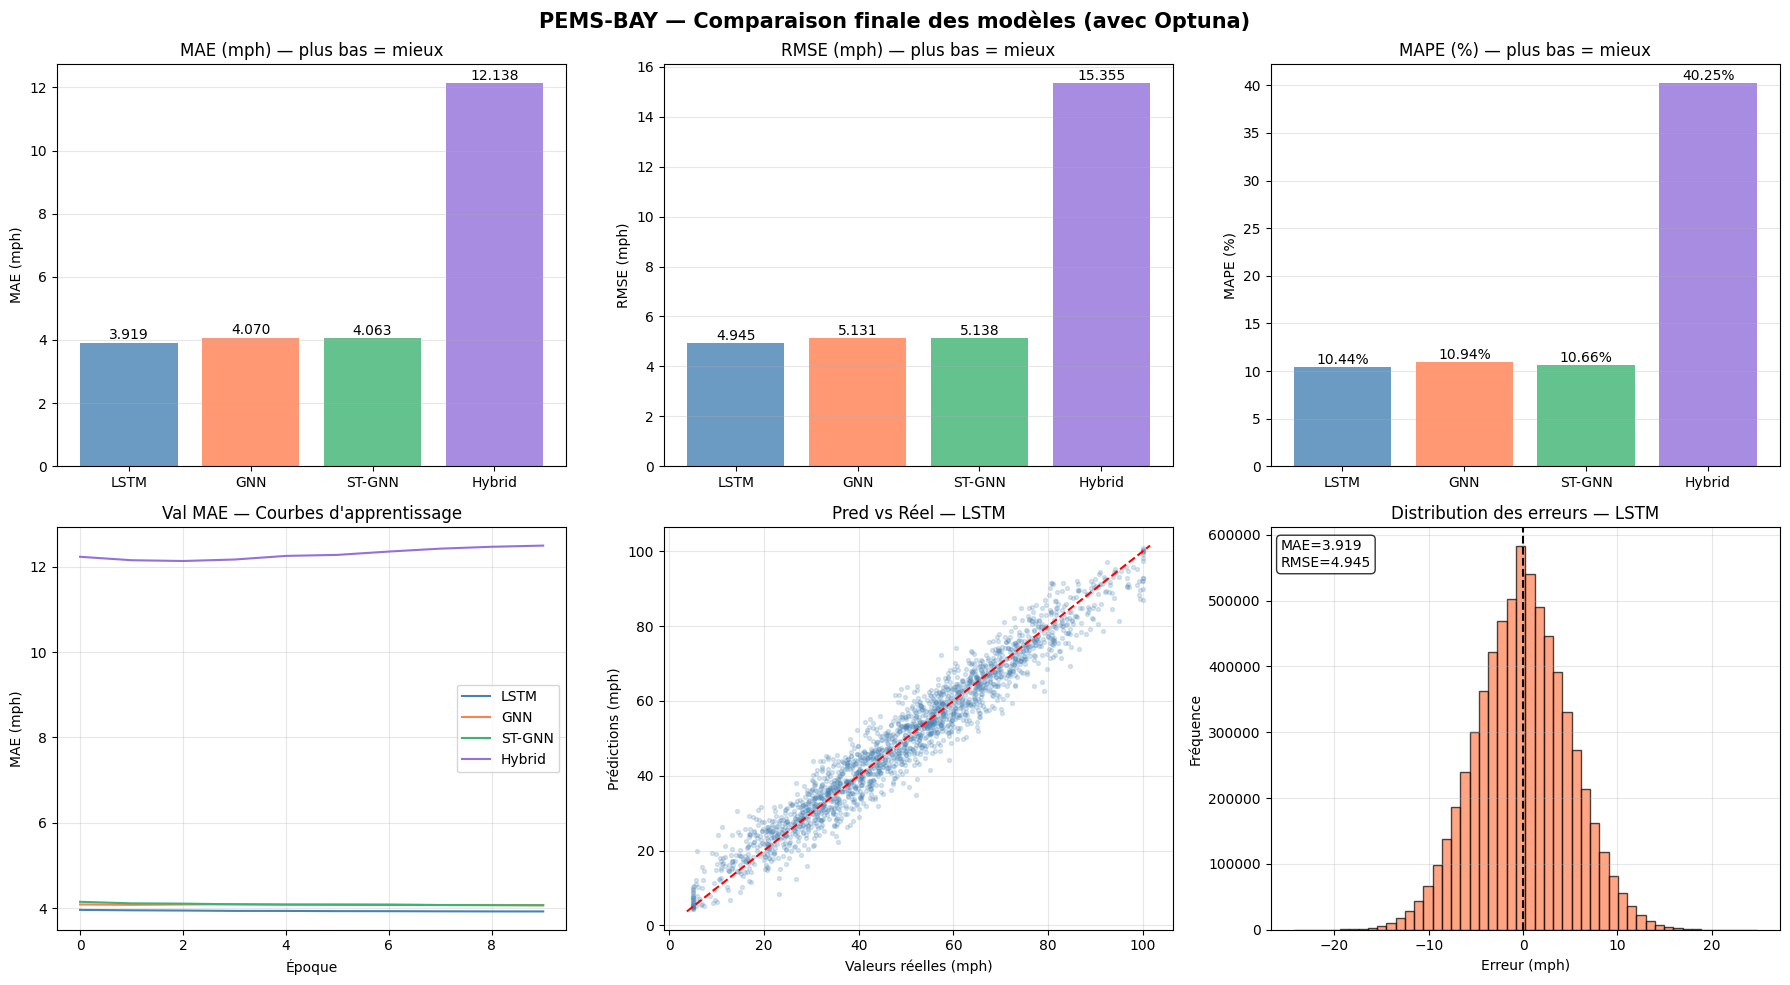


💾 Figure sauvegardée → /kaggle/working/results/pemsbay_comparison.png

📊 TABLEAU RÉCAPITULATIF FINAL — PEMS-BAY
Modèle                  MAE (mph)  RMSE (mph)   MAPE (%)
----------------------------------------------------------------------
LSTM                       3.9189      4.9452      10.44 ← 🏆 MEILLEUR
GNN                        4.0703      5.1306      10.94
ST-GNN                     4.0632      5.1385      10.66
Hybrid                    12.1384     15.3554      40.25

✅ Pipeline PEMS-BAY terminé! Résultats dans : /kaggle/working/results/


In [27]:
# =============================================================================
# SECTION 9: VISUALISATION
# =============================================================================
print("=" * 80)
print("🔴 SECTION 9: VISUALISATION ET COMPARAISON")
print("=" * 80)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('PEMS-BAY — Comparaison finale des modèles (avec Optuna)', fontsize=15, fontweight='bold')

model_list = list(final_results.keys())
names  = [final_results[k]['name']  for k in model_list]
maes   = [final_results[k]['mae']   for k in model_list]
rmses  = [final_results[k]['rmse']  for k in model_list]
mapes  = [final_results[k]['mape']  for k in model_list]
colors = ['steelblue', 'coral', 'mediumseagreen', 'mediumpurple']

# 1. MAE
axes[0, 0].bar(names, maes, color=colors, alpha=0.8)
axes[0, 0].set_title('MAE (mph) — plus bas = mieux')
axes[0, 0].set_ylabel('MAE (mph)')
for i, v in enumerate(maes):
    axes[0, 0].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=10)
axes[0, 0].grid(True, alpha=0.3, axis='y')

# 2. RMSE
axes[0, 1].bar(names, rmses, color=colors, alpha=0.8)
axes[0, 1].set_title('RMSE (mph) — plus bas = mieux')
axes[0, 1].set_ylabel('RMSE (mph)')
for i, v in enumerate(rmses):
    axes[0, 1].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=10)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# 3. MAPE
axes[0, 2].bar(names, mapes, color=colors, alpha=0.8)
axes[0, 2].set_title('MAPE (%) — plus bas = mieux')
axes[0, 2].set_ylabel('MAPE (%)')
for i, v in enumerate(mapes):
    axes[0, 2].text(i, v + 0.01, f'{v:.2f}%', ha='center', va='bottom', fontsize=10)
axes[0, 2].grid(True, alpha=0.3, axis='y')

# 4. Courbes d'apprentissage (Val MAE)
for k, c in zip(model_list, colors):
    axes[1, 0].plot(final_results[k]['history']['val_mae'],
                    label=final_results[k]['name'], color=c)
axes[1, 0].set_title('Val MAE — Courbes d\'apprentissage')
axes[1, 0].set_xlabel('Époque')
axes[1, 0].set_ylabel('MAE (mph)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 5. Scatter pred vs true (meilleur modèle)
best_key = min(model_list, key=lambda k: final_results[k]['mae'])
p = final_results[best_key]['preds'].flatten()
t = final_results[best_key]['targets'].flatten()
sample = np.random.choice(len(p), min(2000, len(p)), replace=False)
axes[1, 1].scatter(t[sample], p[sample], alpha=0.2, s=8, color='steelblue')
mn, mx = min(t.min(), p.min()), max(t.max(), p.max())
axes[1, 1].plot([mn, mx], [mn, mx], 'r--')
axes[1, 1].set_title(f'Pred vs Réel — {final_results[best_key]["name"]}')
axes[1, 1].set_xlabel('Valeurs réelles (mph)')
axes[1, 1].set_ylabel('Prédictions (mph)')
axes[1, 1].grid(True, alpha=0.3)

# 6. Distribution des erreurs (meilleur modèle)
errors = p - t
axes[1, 2].hist(errors, bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[1, 2].axvline(0, color='black', linestyle='--')
axes[1, 2].set_title(f'Distribution des erreurs — {final_results[best_key]["name"]}')
axes[1, 2].set_xlabel('Erreur (mph)')
axes[1, 2].set_ylabel('Fréquence')
axes[1, 2].text(0.02, 0.97, f'MAE={final_results[best_key]["mae"]:.3f}\nRMSE={final_results[best_key]["rmse"]:.3f}',
                transform=axes[1, 2].transAxes, va='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(config.RESULTS_DIR, 'pemsbay_comparison.png')
plt.savefig(fig_path, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n💾 Figure sauvegardée → {fig_path}")

# ── Tableau récapitulatif ──────────────────────────────────────────────────
print("\n" + "=" * 70)
print("📊 TABLEAU RÉCAPITULATIF FINAL — PEMS-BAY")
print("=" * 70)
print(f"{'Modèle':<22} {'MAE (mph)':>10} {'RMSE (mph)':>11} {'MAPE (%)':>10}")
print("-" * 70)
for k in model_list:
    r = final_results[k]
    marker = " ← 🏆 MEILLEUR" if k == best_key else ""
    print(f"{r['name']:<22} {r['mae']:>10.4f} {r['rmse']:>11.4f} {r['mape']:>10.2f}{marker}")
print("=" * 70)
print(f"\n✅ Pipeline PEMS-BAY terminé! Résultats dans : {config.RESULTS_DIR}")

## SECTION 10 — Généralisation sur METR-LA
Cette section applique les 3 approches de transfert pour chacun des 4 modèles :
- **Approche A** : Zero-shot + recalibration BatchNorm (pour ST-GNN et Hybrid "GRU-GNN")
- **Approche B** : Fine-tuning des couches de décodage uniquement
- **Approche C** : Réentraînement complet sur METR-LA

**Pré-requis** : `trained_models`, `best_hyperparams`, `data_loader`, `config`, `edge_index`, `edge_weight` définis en sections précédentes.

In [28]:
# =============================================================================
# SECTION 10 : GÉNÉRALISATION SUR METR-LA
# =============================================================================
print("=" * 80)
print("🔴 SECTION 10 : GÉNÉRALISATION SUR METR-LA")
print("=" * 80)
print("""
Stratégie par modèle :
  LSTM      → recréer avec input_dim=207, transférer lstm+attention+fc1, fc2 réinitialisé
  GNN       → recréer avec num_nodes=207, transférer temporal_encoder+gcn_blocks, decoder OK
  ST-GNN    → recréer avec num_nodes=207, transférer tout + recalibrer BN
  Hybrid    → recréer avec num_nodes=207, transférer tout + recalibrer BN
""")

🔴 SECTION 10 : GÉNÉRALISATION SUR METR-LA

Stratégie par modèle :
  LSTM      → recréer avec input_dim=207, transférer lstm+attention+fc1, fc2 réinitialisé
  GNN       → recréer avec num_nodes=207, transférer temporal_encoder+gcn_blocks, decoder OK
  ST-GNN    → recréer avec num_nodes=207, transférer tout + recalibrer BN
  Hybrid    → recréer avec num_nodes=207, transférer tout + recalibrer BN



In [13]:
# =============================================================================
# 10.1 — CHARGEMENT DES DONNÉES METR-LA
# =============================================================================
print("=" * 60)
print("🔷 10.1 Chargement des données METR-LA")
print("=" * 60)

import pickle
import h5py

# --- Chemins METR-LA (adapter selon votre Google Drive) ---
METR_LA_DATA_PATH = '/kaggle/input/datasets/annnnguyen/metr-la-dataset/METR-LA.h5'
METR_LA_ADJ_PATH  = '/kaggle/input/datasets/annnnguyen/metr-la-dataset/adj_METR-LA.pkl'

NUM_NODES_METR = 207  # METR-LA : 207 capteurs

# ── Chargement données temporelles ──────────────────────────────────────────
def load_metr_h5(file_path):
    """Charge METR-LA depuis HDF5 (clé 'speed/block0_values' ou similaire)."""
    with h5py.File(file_path, 'r') as f:
        keys = list(f.keys())
        print(f"  Clés HDF5 disponibles : {keys}")
        # Cherche la clé contenant les valeurs de vitesse
        for k in ['speed/block0_values', 'df/block0_values', 'data']:
            if k in f or k.split('/')[0] in f:
                try:
                    data = f[k][:]
                    return np.asarray(data, dtype=np.float32)
                except Exception:
                    pass
        # Fallback : première clé trouvée
        root_key = keys[0]
        sub = f[root_key]
        if hasattr(sub, 'keys'):
            sub_key = list(sub.keys())[0]
            data = f[root_key][sub_key][:]
        else:
            data = f[root_key][:]
        return np.asarray(data, dtype=np.float32)

def load_metr_adjacency(pkl_path):
    """Charge la matrice d'adjacence METR-LA depuis pickle."""
    adj_mx = None
    for enc in ['latin1', 'bytes', None]:
        try:
            with open(pkl_path, 'rb') as f:
                raw = pickle.load(f, encoding=enc) if enc else pickle.load(f)
            # Format courant : [sensor_ids_list, sensor_id_to_idx_dict, adj_matrix]
            if isinstance(raw, (list, tuple)) and len(raw) >= 3:
                adj_mx = np.array(raw[2], dtype=np.float32)
            elif isinstance(raw, np.ndarray) and raw.ndim == 2:
                adj_mx = raw.astype(np.float32)
            elif isinstance(raw, dict):
                for v in raw.values():
                    if isinstance(v, np.ndarray) and v.ndim == 2 and v.shape[0] == v.shape[1]:
                        adj_mx = v.astype(np.float32); break
            if adj_mx is not None:
                break
        except Exception:
            continue
    if adj_mx is None:
        raise RuntimeError(f"Impossible de charger la matrice d'adjacence depuis {pkl_path}")
    return adj_mx

def adjacency_to_edge_index_metr(adj_matrix, threshold=0.0, remove_self_loops=True):
    """Convertit matrice d'adjacence en edge_index PyTorch."""
    mask = adj_matrix > threshold
    row, col = np.nonzero(mask)
    w = adj_matrix[row, col].astype(np.float32)
    if remove_self_loops:
        keep = row != col
        row, col, w = row[keep], col[keep], w[keep]
    if row.size == 0:  # graphe vide : ajouter boucle minimale
        row, col, w = np.array([0]), np.array([0]), np.array([1.0], dtype=np.float32)
    edge_index  = torch.from_numpy(np.vstack([row, col])).long()
    edge_weight = torch.from_numpy(w)
    return edge_index.to(config.DEVICE), edge_weight.to(config.DEVICE)

# ── Chargement et vérification ───────────────────────────────────────────────
try:
    print("⏳ Chargement données METR-LA...")
    metr_data_raw = load_metr_h5(METR_LA_DATA_PATH)
    # Assure shape (T, N)
    if metr_data_raw.ndim == 3:
        metr_data_raw = metr_data_raw[:, :, 0]
    print(f"✅ Données : {metr_data_raw.shape} — {metr_data_raw.shape[0]:,} pas × {metr_data_raw.shape[1]} capteurs")
    assert metr_data_raw.shape[1] == NUM_NODES_METR, \
        f"Attendu {NUM_NODES_METR} capteurs, trouvé {metr_data_raw.shape[1]}"

    print("⏳ Chargement matrice d'adjacence METR-LA...")
    metr_adj = load_metr_adjacency(METR_LA_ADJ_PATH)
    print(f"✅ Graphe : {metr_adj.shape} | "
          f"edges : {np.count_nonzero(metr_adj)} | "
          f"symétrique : {np.allclose(metr_adj, metr_adj.T)}")
    assert metr_adj.shape[0] == NUM_NODES_METR, \
        f"Matrice d'adjacence : attendu {NUM_NODES_METR}×{NUM_NODES_METR}, trouvé {metr_adj.shape}"

except Exception as e:
    print(f"❌ Erreur chargement METR-LA : {e}")
    raise

# ── Splits train/val/test (70/10/20) ─────────────────────────────────────────
T = metr_data_raw.shape[0]
n_train = int(0.7 * T)
n_val   = int(0.1 * T)
metr_train_raw = metr_data_raw[:n_train]
metr_val_raw   = metr_data_raw[n_train : n_train + n_val]
metr_test_raw  = metr_data_raw[n_train + n_val :]

# Normalisation avec les stats du train METR-LA uniquement
metr_mean = float(metr_train_raw.mean())
metr_std  = float(metr_train_raw.std() + 1e-8)
metr_train_norm = ((metr_train_raw - metr_mean) / metr_std).astype(np.float32)
metr_val_norm   = ((metr_val_raw   - metr_mean) / metr_std).astype(np.float32)
metr_test_norm  = ((metr_test_raw  - metr_mean) / metr_std).astype(np.float32)

print(f"\n📊 Splits METR-LA :")
print(f"  Train : {metr_train_norm.shape} | Val : {metr_val_norm.shape} | Test : {metr_test_norm.shape}")
print(f"  Normalisation (train) → mean={metr_mean:.3f} mph | std={metr_std:.3f} mph")

# ── DataLoaders (même classe PEMSBAYDataset, agnostique à num_nodes) ──────────
metr_train_ds = PEMSBAYDataset(metr_train_norm, config.SEQ_LEN, config.PRED_LEN)
metr_val_ds   = PEMSBAYDataset(metr_val_norm,   config.SEQ_LEN, config.PRED_LEN)
metr_test_ds  = PEMSBAYDataset(metr_test_norm,  config.SEQ_LEN, config.PRED_LEN)

pin = (config.DEVICE == 'cuda')
metr_train_loader = DataLoader(metr_train_ds, batch_size=config.DEFAULT_BATCH_SIZE,
                               shuffle=True,  num_workers=config.NUM_WORKERS, pin_memory=pin)
metr_val_loader   = DataLoader(metr_val_ds,   batch_size=config.DEFAULT_BATCH_SIZE,
                               shuffle=False, num_workers=config.NUM_WORKERS, pin_memory=pin)
metr_test_loader  = DataLoader(metr_test_ds,  batch_size=config.DEFAULT_BATCH_SIZE,
                               shuffle=False, num_workers=config.NUM_WORKERS, pin_memory=pin)

# ── Graph METR-LA ─────────────────────────────────────────────────────────────
metr_edge_index, metr_edge_weight = adjacency_to_edge_index_metr(metr_adj)
print(f"  edge_index : {metr_edge_index.shape} | edge_weight : {metr_edge_weight.shape}")
print("✅ METR-LA prêt")

🔷 10.1 Chargement des données METR-LA
⏳ Chargement données METR-LA...
  Clés HDF5 disponibles : ['df']
✅ Données : (34272, 207) — 34,272 pas × 207 capteurs
⏳ Chargement matrice d'adjacence METR-LA...
✅ Graphe : (207, 207) | edges : 1722 | symétrique : False

📊 Splits METR-LA :
  Train : (23990, 207) | Val : (3427, 207) | Test : (6855, 207)
  Normalisation (train) → mean=54.406 mph | std=19.494 mph
  edge_index : torch.Size([2, 1515]) | edge_weight : torch.Size([1515])
✅ METR-LA prêt


In [19]:
# =============================================================================
# 10.2 — UTILITAIRES DE TRANSFERT
# =============================================================================
print("=" * 60)
print("🔷 10.2 Utilitaires de transfert")
print("=" * 60)

def denormalize_metr(arr):
    """Dénormalise avec les stats METR-LA."""
    return arr * metr_std + metr_mean

def evaluate_model_metr(model, loader, is_gnn=True):
    """
    Évalue un modèle sur METR-LA.
    Retourne dict avec MAE, RMSE, MAPE dénormalisés.
    """
    model.eval()
    criterion = nn.L1Loss()
    all_preds, all_targets = [], []
    total_loss = 0

    with torch.no_grad():
        for batch in loader:
            x = batch['x'].to(config.DEVICE)  # (B, seq_len, num_nodes)
            y = batch['y'].to(config.DEVICE)  # (B, pred_len, num_nodes)
            if is_gnn:
                pred = model(x, metr_edge_index, metr_edge_weight)
            else:
                pred = model(x)
            loss = criterion(pred, y)
            total_loss += loss.item()
            all_preds.append(pred.cpu().numpy())
            all_targets.append(y.cpu().numpy())

    preds   = np.concatenate(all_preds,   axis=0)
    targets = np.concatenate(all_targets, axis=0)
    # Dénormalisation METR-LA
    preds_d   = denormalize_metr(preds)
    targets_d = denormalize_metr(targets)
    mae, rmse, mape = calculate_metrics(preds_d, targets_d)
    return {'mae': mae, 'rmse': rmse, 'mape': mape,
            'loss': total_loss / len(loader),
            'preds': preds_d, 'targets': targets_d}

def recalibrate_bn_metr(model, n_batches=150):
    """
    Approche A — Recalibration BatchNorm sur METR-LA.
    Met à jour les running_mean/running_var sans modifier les poids.
    """
    has_bn = any(isinstance(m, nn.BatchNorm1d) for m in model.modules())
    if not has_bn:
        print("    (pas de BatchNorm1d dans ce modèle, recalibration ignorée)")
        return
    # Reset complet des stats BN
    for m in model.modules():
        if isinstance(m, nn.BatchNorm1d):
            m.reset_running_stats()
            m.momentum = None  # cumulative moving average
    # Forward pass en mode train() + no_grad() pour maj les stats
    model.train()
    count = 0
    is_gnn = not isinstance(model, LSTMModel_PEMSBAY)
    with torch.no_grad():
        for batch in metr_train_loader:
            x = batch['x'].to(config.DEVICE)
            if is_gnn:
                _ = model(x, metr_edge_index, metr_edge_weight)
            else:
                _ = model(x)
            count += 1
            if count >= n_batches:
                break
    model.eval()
    print(f"    ✓ BatchNorm recalibré sur {count} batches METR-LA")

def finetune_decoder(model, epochs=5, lr=5e-4, patience=3):
    """
    Approche B — Fine-tuning des couches de décodage uniquement.
    Gèle l'encodeur (GNN/LSTM/GRU), entraîne seulement les couches de sortie.
    """
    # 1. Geler tous les paramètres
    for p in model.parameters():
        p.requires_grad = False

    # 2. Débloquer selon le type de modèle
    if isinstance(model, LSTMModel_PEMSBAY):
        # fc1 et fc2 uniquement (attention gardée gelée)
        for n, p in model.named_parameters():
            if any(k in n for k in ['fc1', 'fc2']):
                p.requires_grad = True
    elif isinstance(model, GNNModel_PEMSBAY):
        for n, p in model.named_parameters():
            if 'decoder' in n:
                p.requires_grad = True
    elif isinstance(model, STGNN_PEMSBAY):
        for n, p in model.named_parameters():
            if 'output_proj' in n:
                p.requires_grad = True
    elif isinstance(model, HybridLSTMGNN_PEMSBAY):
        for n, p in model.named_parameters():
            if 'output_layer' in n:
                p.requires_grad = True

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total     = sum(p.numel() for p in model.parameters())
    print(f"    Paramètres entraînables : {n_trainable:,} / {n_total:,} ({100*n_trainable/n_total:.1f}%)")

    optimizer = optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-5
    )
    criterion = nn.L1Loss()
    is_gnn = not isinstance(model, LSTMModel_PEMSBAY)
    best_mae, best_state, patience_ctr = float('inf'), None, 0

    model.train()
    for epoch in range(1, epochs + 1):
        model.train()
        for batch in metr_train_loader:
            x = batch['x'].to(config.DEVICE)
            y = batch['y'].to(config.DEVICE)
            optimizer.zero_grad(set_to_none=True)
            pred = model(x, metr_edge_index, metr_edge_weight) if is_gnn else model(x)
            loss = criterion(pred, y)
            loss.backward()
            clip_grad_norm_(model.parameters(), config.GRADIENT_CLIP_VALUE)
            optimizer.step()

        val_met = evaluate_model_metr(model, metr_val_loader, is_gnn)
        print(f"    Epoch {epoch}/{epochs} | Val MAE : {val_met['mae']:.4f} mph")

        if val_met['mae'] < best_mae:
            best_mae = val_met['mae']
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"    Early stopping à l'époque {epoch}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    # Re-débloquer tous les paramètres pour la suite
    for p in model.parameters():
        p.requires_grad = True
    model.eval()
    return best_mae

def retrain_full_metr(model_class, hp, epochs=None):
    """
    Approche C — Réentraînement complet sur METR-LA.
    Crée un modèle frais avec num_nodes=207, entraîne from scratch.
    """
    epochs = epochs or config.MAX_EPOCHS

    # Instanciation selon le type de modèle
    if model_class == 'lstm':
        model = LSTMModel_PEMSBAY(
            input_dim=NUM_NODES_METR,
            hidden_dim=hp['hidden_dim'], num_layers=hp['num_layers'],
            seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp['dropout']
        ).to(config.DEVICE)
        is_gnn = False
    elif model_class == 'gnn':
        model = GNNModel_PEMSBAY(
            input_dim=1, hidden_dim=hp['hidden_dim'], num_nodes=NUM_NODES_METR,
            num_gcn_blocks=hp['num_gcn_blocks'],
            seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp['dropout']
        ).to(config.DEVICE)
        is_gnn = True
    elif model_class == 'stgnn':
        model = STGNN_PEMSBAY(
            num_nodes=NUM_NODES_METR, input_dim=1, hidden_dim=hp['hidden_dim'],
            num_st_blocks=hp['num_st_blocks'],
            seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp['dropout']
        ).to(config.DEVICE)
        is_gnn = True
    elif model_class == 'hybrid':
        model = HybridLSTMGNN_PEMSBAY(
            num_nodes=NUM_NODES_METR, input_dim=1, hidden_dim=hp['hidden_dim'],
            num_gcn_layers=hp['num_gcn_layers'],
            seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp['dropout']
        ).to(config.DEVICE)
        is_gnn = True
    else:
        raise ValueError(f"model_class inconnu : {model_class}")

    optimizer = optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=config.WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.L1Loss()
    best_mae, best_state, patience_ctr = float('inf'), None, 0

    for epoch in range(1, epochs + 1):
        model.train()
        for batch in metr_train_loader:
            x = batch['x'].to(config.DEVICE)
            y = batch['y'].to(config.DEVICE)
            optimizer.zero_grad(set_to_none=True)
            pred = model(x, metr_edge_index, metr_edge_weight) if is_gnn else model(x)
            loss = criterion(pred, y)
            loss.backward()
            clip_grad_norm_(model.parameters(), config.GRADIENT_CLIP_VALUE)
            optimizer.step()
        scheduler.step()

        val_met = evaluate_model_metr(model, metr_val_loader, is_gnn)
        print(f"  Epoch {epoch:3d}/{epochs} | Val MAE : {val_met['mae']:.4f} mph")

        if val_met['mae'] < best_mae:
            best_mae = val_met['mae']
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= config.EARLY_STOPPING_PATIENCE:
                print(f"  Early stopping à l'époque {epoch}")
                break

    model.load_state_dict(best_state)
    model.eval()
    return model

print("✅ Utilitaires de transfert prêts")

🔷 10.2 Utilitaires de transfert
✅ Utilitaires de transfert prêts


In [33]:
# =============================================================================
# 10.3 — TRANSFERT MODÈLE LSTM
# =============================================================================
print("=" * 60)
print("🔷 10.3 Transfert LSTM → METR-LA")
print("=" * 60)

metr_results = {}
hp_lstm = best_hyperparams['lstm']

# ── APPROCHE A : Zero-shot (recréer avec input_dim=207) ──────────────────────
print("\n▶ Approche A — Zero-shot LSTM")
lstm_metr_A = LSTMModel_PEMSBAY(
    input_dim=NUM_NODES_METR,
    hidden_dim=hp_lstm['hidden_dim'],
    num_layers=hp_lstm['num_layers'],
    seq_len=config.SEQ_LEN,
    pred_len=config.PRED_LEN,
    dropout=hp_lstm['dropout']
).to(config.DEVICE)

src = trained_models['lstm']
with torch.no_grad():
    # ✅ attention and fc1 are safe: their shapes depend only on hidden_dim,
    #    which is the same in both models.
    lstm_metr_A.attention.load_state_dict(src.attention.state_dict())
    lstm_metr_A.fc1.load_state_dict(src.fc1.state_dict())
    # ❌ lstm: weight_ih shape is (4*hidden, input_dim) → 325 ≠ 207, cannot transfer
    # ❌ fc2:  shape is (hidden, input_dim*pred_len)    → 325 ≠ 207, cannot transfer
    print("  Transféré : attention, fc1 | Réinitialisé : lstm (input_dim changé), fc2")

# Pas de BN dans le LSTM → pas de recalibration nécessaire
met_A = evaluate_model_metr(lstm_metr_A, metr_test_loader, is_gnn=False)
print(f"  MAE={met_A['mae']:.4f} | RMSE={met_A['rmse']:.4f} | MAPE={met_A['mape']:.2f}%")

# ── APPROCHE B : Fine-tuning fc1+fc2 ────────────────────────────────────────
print("\n▶ Approche B — Fine-tuning LSTM (fc1+fc2)")
import copy
lstm_metr_B = copy.deepcopy(lstm_metr_A)
finetune_decoder(lstm_metr_B, epochs=5, lr=5e-4, patience=3)
met_B = evaluate_model_metr(lstm_metr_B, metr_test_loader, is_gnn=False)
print(f"  MAE={met_B['mae']:.4f} | RMSE={met_B['rmse']:.4f} | MAPE={met_B['mape']:.2f}%")

# ── APPROCHE C : Réentraînement complet ─────────────────────────────────────
print("\n▶ Approche C — Réentraînement complet LSTM sur METR-LA")
lstm_metr_C = retrain_full_metr('lstm', hp_lstm)
met_C = evaluate_model_metr(lstm_metr_C, metr_test_loader, is_gnn=False)
print(f"  MAE={met_C['mae']:.4f} | RMSE={met_C['rmse']:.4f} | MAPE={met_C['mape']:.2f}%")

# Sélection du meilleur
best_lstm_metr = min(
    [('A', met_A, lstm_metr_A), ('B', met_B, lstm_metr_B), ('C', met_C, lstm_metr_C)],
    key=lambda x: x[1]['mae']
)
print(f"\n  🏆 Meilleure approche LSTM : {best_lstm_metr[0]} (MAE={best_lstm_metr[1]['mae']:.4f})")
metr_results['lstm'] = {
    'name': 'LSTM', 'best_approach': best_lstm_metr[0],
    'A': met_A, 'B': met_B, 'C': met_C,
    'best': best_lstm_metr[1], 'model': best_lstm_metr[2]
}

🔷 10.3 Transfert LSTM → METR-LA

▶ Approche A — Zero-shot LSTM
  Transféré : attention, fc1 | Réinitialisé : lstm (input_dim changé), fc2
  MAE=16.7054 | RMSE=23.1536 | MAPE=31.37%

▶ Approche B — Fine-tuning LSTM (fc1+fc2)
    Paramètres entraînables : 48,621 / 353,773 (13.7%)
    Epoch 1/5 | Val MAE : 7.9643 mph
    Epoch 2/5 | Val MAE : 6.9638 mph
    Epoch 3/5 | Val MAE : 6.5067 mph
    Epoch 4/5 | Val MAE : 6.2846 mph
    Epoch 5/5 | Val MAE : 6.1936 mph
  MAE=7.1104 | RMSE=14.5419 | MAPE=15.65%

▶ Approche C — Réentraînement complet LSTM sur METR-LA
  Epoch   1/10 | Val MAE : 6.0391 mph
  Epoch   2/10 | Val MAE : 5.5277 mph
  Epoch   3/10 | Val MAE : 5.3155 mph
  Epoch   4/10 | Val MAE : 5.2090 mph
  Epoch   5/10 | Val MAE : 5.1945 mph
  Epoch   6/10 | Val MAE : 5.1584 mph
  Epoch   7/10 | Val MAE : 5.1617 mph
  Epoch   8/10 | Val MAE : 5.1890 mph
  Epoch   9/10 | Val MAE : 5.1612 mph
  Epoch  10/10 | Val MAE : 5.1631 mph
  MAE=5.8075 | RMSE=13.0910 | MAPE=13.44%

  🏆 Meilleure a

In [34]:
# =============================================================================
# 10.4 — TRANSFERT MODÈLE GNN
# =============================================================================
print("=" * 60)
print("🔷 10.4 Transfert GNN → METR-LA")
print("=" * 60)

hp_gnn = best_hyperparams['gnn']

# ── APPROCHE A : Zero-shot GNN ───────────────────────────────────────────────
# GCNConv(in, out) est indépendant de num_nodes → transfert complet possible
print("\n▶ Approche A — Zero-shot GNN")
gnn_metr_A = GNNModel_PEMSBAY(
    input_dim=1, hidden_dim=hp_gnn['hidden_dim'],
    num_nodes=NUM_NODES_METR,           # 207
    num_gcn_blocks=hp_gnn['num_gcn_blocks'],
    seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp_gnn['dropout']
).to(config.DEVICE)

src = trained_models['gnn']
with torch.no_grad():
    # temporal_encoder LSTM(1, hidden_dim) → identique (input=1 indépendant de N)
    gnn_metr_A.temporal_encoder.load_state_dict(src.temporal_encoder.state_dict())
    # gcn_blocks : GCNConv(H,H) → indépendant de N
    gnn_metr_A.gcn_blocks.load_state_dict(src.gcn_blocks.state_dict())
    # decoder Linear(H → pred_len) → identique
    gnn_metr_A.decoder.load_state_dict(src.decoder.state_dict())
    print("  Transféré : temporal_encoder, gcn_blocks, decoder (100% compatible)")

# GNN n'a pas de BatchNorm → pas de recalibration
met_A = evaluate_model_metr(gnn_metr_A, metr_test_loader, is_gnn=True)
print(f"  MAE={met_A['mae']:.4f} | RMSE={met_A['rmse']:.4f} | MAPE={met_A['mape']:.2f}%")

# ── APPROCHE B : Fine-tuning decoder ────────────────────────────────────────
print("\n▶ Approche B — Fine-tuning GNN (decoder)")
gnn_metr_B = copy.deepcopy(gnn_metr_A)
finetune_decoder(gnn_metr_B, epochs=5, lr=5e-4, patience=3)
met_B = evaluate_model_metr(gnn_metr_B, metr_test_loader, is_gnn=True)
print(f"  MAE={met_B['mae']:.4f} | RMSE={met_B['rmse']:.4f} | MAPE={met_B['mape']:.2f}%")

# ── APPROCHE C : Réentraînement complet ─────────────────────────────────────
print("\n▶ Approche C — Réentraînement complet GNN sur METR-LA")
gnn_metr_C = retrain_full_metr('gnn', hp_gnn)
met_C = evaluate_model_metr(gnn_metr_C, metr_test_loader, is_gnn=True)
print(f"  MAE={met_C['mae']:.4f} | RMSE={met_C['rmse']:.4f} | MAPE={met_C['mape']:.2f}%")

best_gnn_metr = min(
    [('A', met_A, gnn_metr_A), ('B', met_B, gnn_metr_B), ('C', met_C, gnn_metr_C)],
    key=lambda x: x[1]['mae']
)
print(f"\n  🏆 Meilleure approche GNN : {best_gnn_metr[0]} (MAE={best_gnn_metr[1]['mae']:.4f})")
metr_results['gnn'] = {
    'name': 'GNN', 'best_approach': best_gnn_metr[0],
    'A': met_A, 'B': met_B, 'C': met_C,
    'best': best_gnn_metr[1], 'model': best_gnn_metr[2]
}

🔷 10.4 Transfert GNN → METR-LA

▶ Approche A — Zero-shot GNN
  Transféré : temporal_encoder, gcn_blocks, decoder (100% compatible)
  MAE=5.7335 | RMSE=10.9161 | MAPE=11.00%

▶ Approche B — Fine-tuning GNN (decoder)
    Paramètres entraînables : 16,899 / 381,187 (4.4%)
    Epoch 1/5 | Val MAE : 3.6362 mph
    Epoch 2/5 | Val MAE : 3.5405 mph
    Epoch 3/5 | Val MAE : 3.5436 mph
    Epoch 4/5 | Val MAE : 3.4951 mph
    Epoch 5/5 | Val MAE : 3.5324 mph
  MAE=3.8293 | RMSE=9.0641 | MAPE=8.90%

▶ Approche C — Réentraînement complet GNN sur METR-LA
  Epoch   1/10 | Val MAE : 3.1338 mph
  Epoch   2/10 | Val MAE : 3.0420 mph
  Epoch   3/10 | Val MAE : 3.0431 mph
  Epoch   4/10 | Val MAE : 3.0280 mph
  Epoch   5/10 | Val MAE : 3.0210 mph
  Epoch   6/10 | Val MAE : 3.0459 mph
  Epoch   7/10 | Val MAE : 3.0149 mph
  Epoch   8/10 | Val MAE : 2.9724 mph
  Epoch   9/10 | Val MAE : 2.9674 mph
  Epoch  10/10 | Val MAE : 2.9879 mph
  MAE=3.2100 | RMSE=8.1819 | MAPE=7.47%

  🏆 Meilleure approche GNN : C

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# 🔁 RÉCUPÉRATION COMPLÈTE — Toutes les variables pour Section 10.5 → 10.8
# ══════════════════════════════════════════════════════════════════════════════
import torch, json, os, copy
import numpy as np

# ── 1. best_hyperparams ───────────────────────────────────────────────────────
with open('/kaggle/working/results/best_hyperparameters.json', 'r') as f:
    best_hyperparams = json.load(f)
print("✅ best_hyperparams chargé")

# ── 2. final_results (Section 8) ──────────────────────────────────────────────
with open('/kaggle/working/results/final_results_pems_bay.json', 'r') as f:
    final_results = json.load(f)
print("✅ final_results chargé")

# ── 3. trained_models (Section 7) ─────────────────────────────────────────────
trained_models = {}

hp = best_hyperparams['lstm']
m = LSTMModel_PEMSBAY(
    input_dim=config.NUM_NODES, hidden_dim=hp['hidden_dim'],
    num_layers=hp['num_layers'], seq_len=config.SEQ_LEN,
    pred_len=config.PRED_LEN, dropout=hp['dropout']
).to(config.DEVICE)
m.load_state_dict(torch.load('/kaggle/working/results/best_lstm.pth', map_location=config.DEVICE, weights_only=False)['model_state'])
m.eval(); trained_models['lstm'] = m
print("✅ LSTM chargé")

hp = best_hyperparams['gnn']
m = GNNModel_PEMSBAY(
    input_dim=1, hidden_dim=hp['hidden_dim'],
    num_nodes=config.NUM_NODES, num_gcn_blocks=hp['num_gcn_blocks'],
    seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp['dropout']
).to(config.DEVICE)
m.load_state_dict(torch.load('/kaggle/working/results/best_gnn.pth', map_location=config.DEVICE, weights_only=False)['model_state'])
m.eval(); trained_models['gnn'] = m
print("✅ GNN chargé")

hp = best_hyperparams['stgnn']
m = STGNN_PEMSBAY(
    num_nodes=config.NUM_NODES, input_dim=1,
    hidden_dim=hp['hidden_dim'], num_st_blocks=hp['num_st_blocks'],
    seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp['dropout']
).to(config.DEVICE)
m.load_state_dict(torch.load('/kaggle/working/results/best_stgnn.pth', map_location=config.DEVICE, weights_only=False)['model_state'])
m.eval(); trained_models['stgnn'] = m
print("✅ ST-GNN chargé")

hp = best_hyperparams['hybrid']
m = HybridLSTMGNN_PEMSBAY(
    num_nodes=config.NUM_NODES, input_dim=1,
    hidden_dim=hp['hidden_dim'], num_gcn_layers=hp['num_gcn_layers'],
    seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp['dropout']
).to(config.DEVICE)
m.load_state_dict(torch.load('/kaggle/working/results/best_hybrid.pth', map_location=config.DEVICE, weights_only=False)['model_state'])
m.eval(); trained_models['hybrid'] = m
print("✅ Hybrid chargé")

# ── 4. metr_results — 
metr_results = {}

metr_results['lstm'] = {
    'name': 'LSTM', 'best_approach': 'C',
    'A': {'mae': 16.7054, 'rmse': 23.1536, 'mape': 31.37},
    'B': {'mae': 7.1104,  'rmse': 14.5419, 'mape': 15.65},
    'C': {'mae': 5.8075,  'rmse': 13.0910, 'mape': 13.44},
    'best': {'mae': 5.8075, 'rmse': 13.0910, 'mape': 13.44},
}

metr_results['gnn'] = {
    'name': 'GNN', 'best_approach': 'C',
    'A': {'mae': 5.7335, 'rmse': 10.9161, 'mape': 11.00},
    'B': {'mae': 3.8293, 'rmse': 9.0641,  'mape': 8.90},
    'C': {'mae': 3.2100, 'rmse': 8.1819,  'mape': 7.47},
    'best': {'mae': 3.2100, 'rmse': 8.1819, 'mape': 7.47},
}

print("✅ metr_results LSTM + GNN restaurés")
print("\n🟢 Toutes les variables prêtes")

✅ best_hyperparams chargé
✅ final_results chargé
✅ LSTM chargé
✅ GNN chargé
✅ ST-GNN chargé
✅ Hybrid chargé
✅ metr_results LSTM + GNN restaurés

🟢 Toutes les variables prêtes


In [29]:
# =============================================================================
# 10.5 — TRANSFERT MODÈLE ST-GNN
# =============================================================================
import copy
print("=" * 60)
print("🔷 10.5 Transfert ST-GNN → METR-LA")
print("=" * 60)

hp_stgnn = best_hyperparams['stgnn']

# ── APPROCHE A : Zero-shot + recalibration BN ────────────────────────────────
# ST-GNN : GCNConv(H,H) + Conv1d(H,H,k3) → tous indépendants de num_nodes
# output_proj Linear(seq_len*H → pred_len) → identique
print("\n▶ Approche A — Zero-shot + BN recalibration ST-GNN")
stgnn_metr_A = STGNN_PEMSBAY(
    num_nodes=NUM_NODES_METR, input_dim=1,
    hidden_dim=hp_stgnn['hidden_dim'],
    num_st_blocks=hp_stgnn['num_st_blocks'],
    seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp_stgnn['dropout']
).to(config.DEVICE)

src = trained_models['stgnn']
# Transfert complet strict=False pour robustesse
result = stgnn_metr_A.load_state_dict(src.state_dict(), strict=False)
print(f"  Clés manquantes : {result.missing_keys}")
print(f"  Clés inattendues : {result.unexpected_keys}")

# Recalibration BN (ST-GNN n'a pas de BN explicite ici, mais par sécurité)
recalibrate_bn_metr(stgnn_metr_A, n_batches=150)
stgnn_metr_A.eval()
met_A = evaluate_model_metr(stgnn_metr_A, metr_test_loader, is_gnn=True)
print(f"  MAE={met_A['mae']:.4f} | RMSE={met_A['rmse']:.4f} | MAPE={met_A['mape']:.2f}%")

# ── APPROCHE B : Fine-tuning output_proj ────────────────────────────────────
print("\n▶ Approche B — Fine-tuning ST-GNN (output_proj)")
stgnn_metr_B = copy.deepcopy(stgnn_metr_A)
finetune_decoder(stgnn_metr_B, epochs=5, lr=5e-4, patience=3)
met_B = evaluate_model_metr(stgnn_metr_B, metr_test_loader, is_gnn=True)
print(f"  MAE={met_B['mae']:.4f} | RMSE={met_B['rmse']:.4f} | MAPE={met_B['mape']:.2f}%")

# ── APPROCHE C : Réentraînement complet ─────────────────────────────────────
print("\n▶ Approche C — Réentraînement complet ST-GNN sur METR-LA")
stgnn_metr_C = retrain_full_metr('stgnn', hp_stgnn)
met_C = evaluate_model_metr(stgnn_metr_C, metr_test_loader, is_gnn=True)
print(f"  MAE={met_C['mae']:.4f} | RMSE={met_C['rmse']:.4f} | MAPE={met_C['mape']:.2f}%")

best_stgnn_metr = min(
    [('A', met_A, stgnn_metr_A), ('B', met_B, stgnn_metr_B), ('C', met_C, stgnn_metr_C)],
    key=lambda x: x[1]['mae']
)
print(f"\n  🏆 Meilleure approche ST-GNN : {best_stgnn_metr[0]} (MAE={best_stgnn_metr[1]['mae']:.4f})")
metr_results['stgnn'] = {
    'name': 'ST-GNN', 'best_approach': best_stgnn_metr[0],
    'A': met_A, 'B': met_B, 'C': met_C,
    'best': best_stgnn_metr[1], 'model': best_stgnn_metr[2]
}

🔷 10.5 Transfert ST-GNN → METR-LA

▶ Approche A — Zero-shot + BN recalibration ST-GNN
  Clés manquantes : []
  Clés inattendues : []
    (pas de BatchNorm1d dans ce modèle, recalibration ignorée)
  MAE=5.6691 | RMSE=11.0403 | MAPE=11.14%

▶ Approche B — Fine-tuning ST-GNN (output_proj)
    Paramètres entraînables : 426,755 / 624,387 (68.3%)
    Epoch 1/5 | Val MAE : 3.1522 mph
    Epoch 2/5 | Val MAE : 3.0733 mph
    Epoch 3/5 | Val MAE : 3.0662 mph
    Epoch 4/5 | Val MAE : 3.0197 mph
    Epoch 5/5 | Val MAE : 3.0646 mph
  MAE=3.2524 | RMSE=8.2936 | MAPE=7.64%

▶ Approche C — Réentraînement complet ST-GNN sur METR-LA
  Epoch   1/10 | Val MAE : 3.0531 mph
  Epoch   2/10 | Val MAE : 3.2235 mph
  Epoch   3/10 | Val MAE : 3.0012 mph
  Epoch   4/10 | Val MAE : 3.0708 mph
  Epoch   5/10 | Val MAE : 3.0633 mph
  Epoch   6/10 | Val MAE : 2.9644 mph
  Epoch   7/10 | Val MAE : 3.1009 mph
  Epoch   8/10 | Val MAE : 2.9517 mph
  Epoch   9/10 | Val MAE : 2.9354 mph
  Epoch  10/10 | Val MAE : 2.921

In [30]:
# =============================================================================
# 10.6 — TRANSFERT MODÈLE HYBRID GRU-GNN
# =============================================================================
print("=" * 60)
print("🔷 10.6 Transfert Hybrid GRU-GNN → METR-LA")
print("=" * 60)

hp_hybrid = best_hyperparams['hybrid']

# ── APPROCHE A : Zero-shot + recalibration BN ────────────────────────────────
# Hybrid : GCNConv(1,H) puis GRU(H,H) puis Linear(H*2→pred_len)
# GCNConv(1,H) → indépendant de N ✓
# GRU(H,H)     → indépendant de N ✓
# output_layer Linear(H*2→pred_len) → identique ✓
print("\n▶ Approche A — Zero-shot + BN recalibration Hybrid")
hybrid_metr_A = HybridLSTMGNN_PEMSBAY(
    num_nodes=NUM_NODES_METR, input_dim=1,
    hidden_dim=hp_hybrid['hidden_dim'],
    num_gcn_layers=hp_hybrid['num_gcn_layers'],
    seq_len=config.SEQ_LEN, pred_len=config.PRED_LEN, dropout=hp_hybrid['dropout']
).to(config.DEVICE)

src = trained_models['hybrid']
result = hybrid_metr_A.load_state_dict(src.state_dict(), strict=False)
print(f"  Clés manquantes : {result.missing_keys}")
print(f"  Clés inattendues : {result.unexpected_keys}")

recalibrate_bn_metr(hybrid_metr_A, n_batches=150)
hybrid_metr_A.eval()
met_A = evaluate_model_metr(hybrid_metr_A, metr_test_loader, is_gnn=True)
print(f"  MAE={met_A['mae']:.4f} | RMSE={met_A['rmse']:.4f} | MAPE={met_A['mape']:.2f}%")

# ── APPROCHE B : Fine-tuning output_layer ───────────────────────────────────
print("\n▶ Approche B — Fine-tuning Hybrid (output_layer)")
hybrid_metr_B = copy.deepcopy(hybrid_metr_A)
finetune_decoder(hybrid_metr_B, epochs=5, lr=5e-4, patience=3)
met_B = evaluate_model_metr(hybrid_metr_B, metr_test_loader, is_gnn=True)
print(f"  MAE={met_B['mae']:.4f} | RMSE={met_B['rmse']:.4f} | MAPE={met_B['mape']:.2f}%")

# ── APPROCHE C : Réentraînement complet ─────────────────────────────────────
print("\n▶ Approche C — Réentraînement complet Hybrid sur METR-LA")
hybrid_metr_C = retrain_full_metr('hybrid', hp_hybrid)
met_C = evaluate_model_metr(hybrid_metr_C, metr_test_loader, is_gnn=True)
print(f"  MAE={met_C['mae']:.4f} | RMSE={met_C['rmse']:.4f} | MAPE={met_C['mape']:.2f}%")

best_hybrid_metr = min(
    [('A', met_A, hybrid_metr_A), ('B', met_B, hybrid_metr_B), ('C', met_C, hybrid_metr_C)],
    key=lambda x: x[1]['mae']
)
print(f"\n  🏆 Meilleure approche Hybrid : {best_hybrid_metr[0]} (MAE={best_hybrid_metr[1]['mae']:.4f})")
metr_results['hybrid'] = {
    'name': 'Hybrid GRU-GNN', 'best_approach': best_hybrid_metr[0],
    'A': met_A, 'B': met_B, 'C': met_C,
    'best': best_hybrid_metr[1], 'model': best_hybrid_metr[2]
}

🔷 10.6 Transfert Hybrid GRU-GNN → METR-LA

▶ Approche A — Zero-shot + BN recalibration Hybrid
  Clés manquantes : []
  Clés inattendues : []
    (pas de BatchNorm1d dans ce modèle, recalibration ignorée)
  MAE=12.5544 | RMSE=17.2089 | MAPE=24.21%

▶ Approche B — Fine-tuning Hybrid (output_layer)
    Paramètres entraînables : 33,283 / 577,667 (5.8%)
    Epoch 1/5 | Val MAE : 7.1502 mph
    Epoch 2/5 | Val MAE : 7.0630 mph
    Epoch 3/5 | Val MAE : 6.9694 mph
    Epoch 4/5 | Val MAE : 6.8723 mph
    Epoch 5/5 | Val MAE : 6.9114 mph
  MAE=7.4917 | RMSE=13.9353 | MAPE=19.46%

▶ Approche C — Réentraînement complet Hybrid sur METR-LA
  Epoch   1/10 | Val MAE : 6.5874 mph
  Epoch   2/10 | Val MAE : 6.4529 mph
  Epoch   3/10 | Val MAE : 6.4433 mph
  Epoch   4/10 | Val MAE : 6.3411 mph
  Epoch   5/10 | Val MAE : 6.4664 mph
  Epoch   6/10 | Val MAE : 6.3187 mph
  Epoch   7/10 | Val MAE : 6.3286 mph
  Epoch   8/10 | Val MAE : 6.3299 mph
  Epoch   9/10 | Val MAE : 6.3394 mph
  Epoch  10/10 | Val M

In [32]:
# =============================================================================
# 10.7 — TABLEAU COMPARATIF FINAL
# =============================================================================
print("=" * 80)
print("🔴 SECTION 10.7 : TABLEAU COMPARATIF PEMS-BAY vs METR-LA")
print("=" * 80)

header = f"{'Modèle':<18} {'Approche':>10} | {'MAE PEMS-BAY':>13} {'MAE METR-LA':>13} {'ΔMAE':>8}"
print("\n📊 COMPARAISON PAR APPROCHE (MAE en mph)")
print("-" * 70)
print(header)
print("-" * 70)

model_keys = ['lstm', 'gnn', 'stgnn', 'hybrid']
for k in model_keys:
    pems_mae = float(final_results[k]['mae'])   # ← float() ajouté
    for appr in ['A', 'B', 'C']:
        metr_mae = float(metr_results[k][appr]['mae'])   # ← float() ajouté
        delta    = metr_mae - pems_mae
        best_marker = " ← best" if appr == metr_results[k]['best_approach'] else ""
        print(f"{metr_results[k]['name']:<18} {appr:>10} | {pems_mae:>13.4f} {metr_mae:>13.4f} {delta:>+8.4f}{best_marker}")
    print("-" * 70)

print("\n📊 SYNTHÈSE — MEILLEURE APPROCHE PAR MODÈLE")
print("=" * 80)
print(f"{'Modèle':<18} {'Best appr.':>10} | {'MAE PEMS':>10} {'RMSE PEMS':>11} | {'MAE METR':>10} {'RMSE METR':>11} {'MAPE METR':>11}")
print("-" * 80)

for k in model_keys:
    r_pems = final_results[k]
    r_metr = metr_results[k]['best']
    ba     = metr_results[k]['best_approach']
    print(f"{metr_results[k]['name']:<18} {ba:>10} | "
          f"{float(r_pems['mae']):>10.4f} {float(r_pems['rmse']):>11.4f} | "   # ← float() ajouté
          f"{float(r_metr['mae']):>10.4f} {float(r_metr['rmse']):>11.4f} {float(r_metr['mape']):>10.2f}%")   # ← float() ajouté
print("=" * 80)

# ── Sauvegarde JSON ───────────────────────────────────────────────────────────
metr_summary = {}
for k in model_keys:
    metr_summary[k] = {
        'name': metr_results[k]['name'],
        'best_approach': metr_results[k]['best_approach'],
        'pems_bay': {
            'mae':  float(final_results[k]['mae']),    # ← float() ajouté
            'rmse': float(final_results[k]['rmse']),   # ← float() ajouté
            'mape': float(final_results[k]['mape'])    # ← float() ajouté
        },
        'metr_la': {
            'A': {'mae': float(metr_results[k]['A']['mae']), 'rmse': float(metr_results[k]['A']['rmse']), 'mape': float(metr_results[k]['A']['mape'])},
            'B': {'mae': float(metr_results[k]['B']['mae']), 'rmse': float(metr_results[k]['B']['rmse']), 'mape': float(metr_results[k]['B']['mape'])},
            'C': {'mae': float(metr_results[k]['C']['mae']), 'rmse': float(metr_results[k]['C']['rmse']), 'mape': float(metr_results[k]['C']['mape'])},
        }
    }

res_path = os.path.join(config.RESULTS_DIR, 'generalisation_metr_la.json')
with open(res_path, 'w') as f:
    json.dump(metr_summary, f, indent=4)   # ← default=str supprimé (plus nécessaire)
print(f"\n💾 Résultats sauvegardés → {res_path}")

🔴 SECTION 10.7 : TABLEAU COMPARATIF PEMS-BAY vs METR-LA

📊 COMPARAISON PAR APPROCHE (MAE en mph)
----------------------------------------------------------------------
Modèle               Approche |  MAE PEMS-BAY   MAE METR-LA     ΔMAE
----------------------------------------------------------------------
LSTM                        A |        3.9189       16.7054 +12.7865
LSTM                        B |        3.9189        7.1104  +3.1915
LSTM                        C |        3.9189        5.8075  +1.8886 ← best
----------------------------------------------------------------------
GNN                         A |        4.0703        5.7335  +1.6632
GNN                         B |        4.0703        3.8293  -0.2410
GNN                         C |        4.0703        3.2100  -0.8603 ← best
----------------------------------------------------------------------
ST-GNN                      A |        4.0632        5.6691  +1.6058
ST-GNN                      B |        4.0632        

🔷 10.8 Visualisation de la généralisation


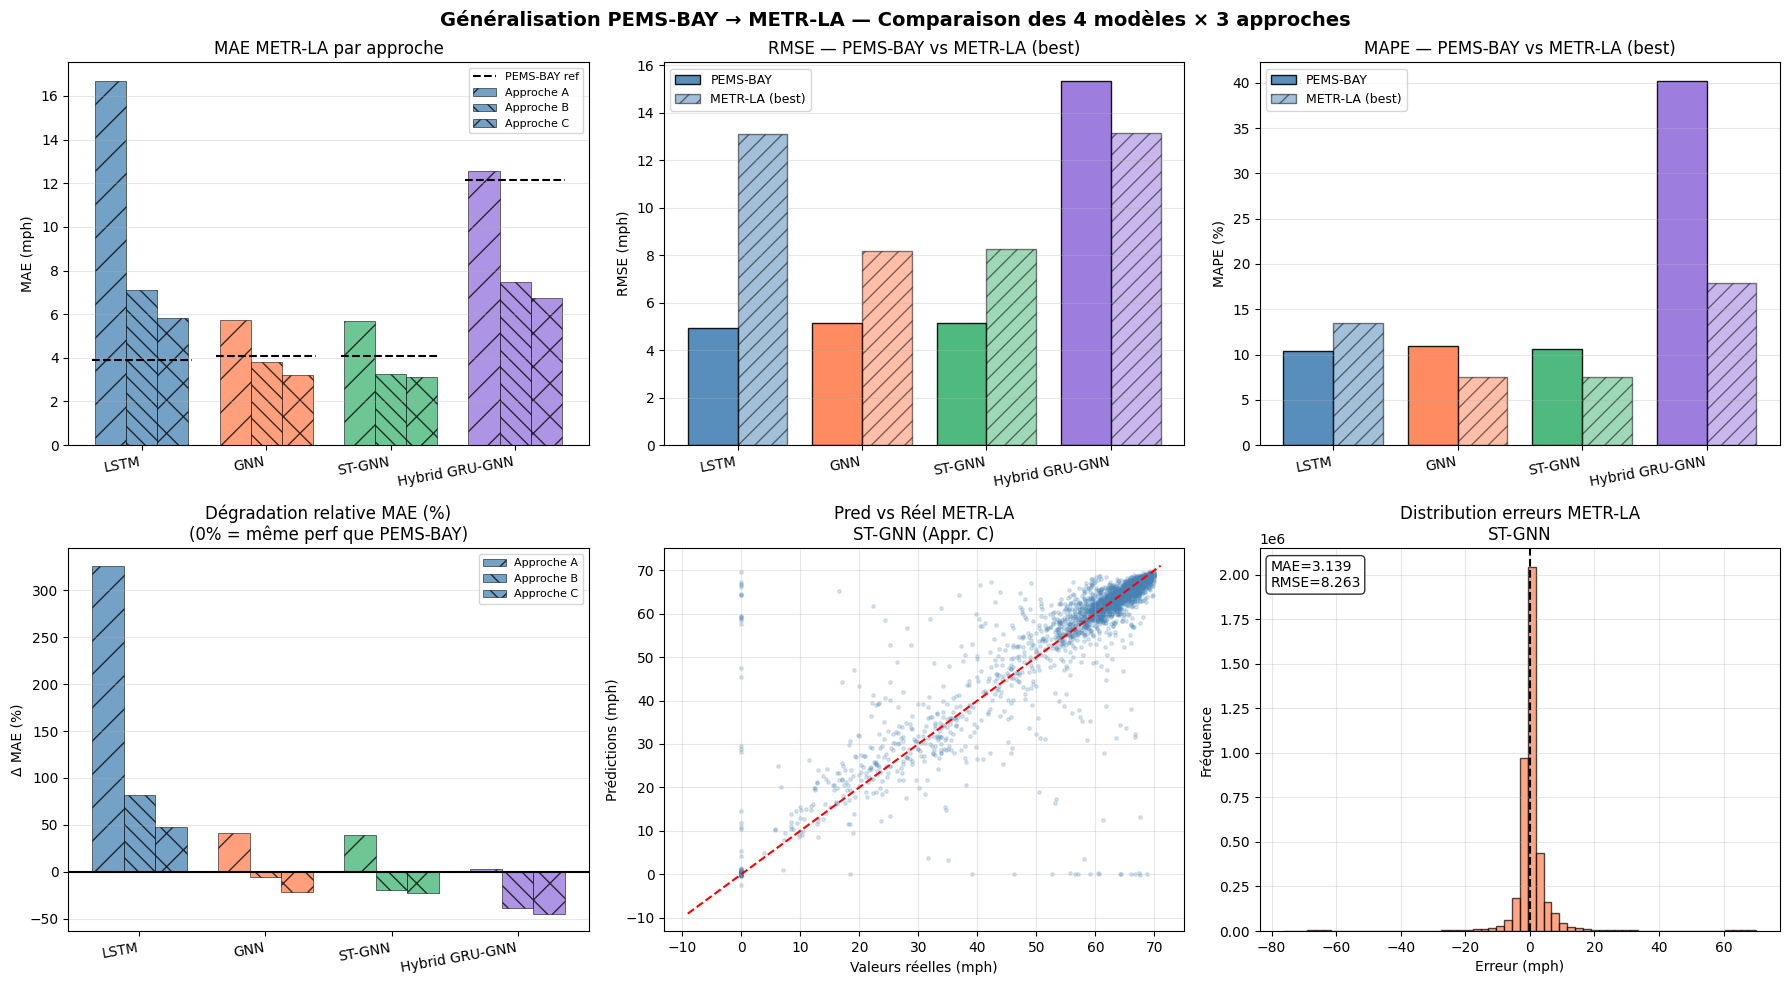


💾 Figure sauvegardée → /kaggle/working/results/generalisation_metr_la.png

✅ Section 10 terminée — Généralisation METR-LA complète!


In [34]:
# =============================================================================
# 10.8 — VISUALISATION DE LA GÉNÉRALISATION
# =============================================================================
print("=" * 60)
print("🔷 10.8 Visualisation de la généralisation")
print("=" * 60)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Généralisation PEMS-BAY → METR-LA — Comparaison des 4 modèles × 3 approches',
             fontsize=14, fontweight='bold')

model_keys  = ['lstm', 'gnn', 'stgnn', 'hybrid']
model_names = [metr_results[k]['name'] for k in model_keys]
colors      = ['steelblue', 'coral', 'mediumseagreen', 'mediumpurple']
approach_styles = {'A': '/', 'B': '\\\\', 'C': 'x'}

# 1. MAE par modèle et approche (grouped bar)
ax = axes[0, 0]
x = np.arange(len(model_keys))
w = 0.25
for i, (appr, hatch) in enumerate(approach_styles.items()):
    maes = [metr_results[k][appr]['mae'] for k in model_keys]
    bars = ax.bar(x + (i - 1) * w, maes, w, label=f'Approche {appr}',
                  color=[c for c in colors], alpha=0.75, hatch=hatch, edgecolor='black', linewidth=0.5)
# Ligne PEMS-BAY de référence
for i, k in enumerate(model_keys):
    ax.hlines(float(final_results[k]['mae']), i - 0.4, i + 0.4,
              colors='black', linestyles='--', linewidth=1.5, label='PEMS-BAY ref' if i == 0 else '')
ax.set_xticks(x); ax.set_xticklabels(model_names, rotation=10, ha='right')
ax.set_title('MAE METR-LA par approche')
ax.set_ylabel('MAE (mph)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')

# 2. RMSE par modèle (meilleure approche)
ax = axes[0, 1]
rmse_pems = [float(final_results[k]['rmse']) for k in model_keys]
rmse_metr = [metr_results[k]['best']['rmse'] for k in model_keys]
xp = np.arange(len(model_keys))
ax.bar(xp - 0.2, rmse_pems, 0.4, label='PEMS-BAY', color=colors, alpha=0.9, edgecolor='black')
ax.bar(xp + 0.2, rmse_metr, 0.4, label='METR-LA (best)', color=colors, alpha=0.5,
       edgecolor='black', hatch='//')
ax.set_xticks(xp); ax.set_xticklabels(model_names, rotation=10, ha='right')
ax.set_title('RMSE — PEMS-BAY vs METR-LA (best)')
ax.set_ylabel('RMSE (mph)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

# 3. MAPE par modèle (meilleure approche)
ax = axes[0, 2]
mape_pems = [float(final_results[k]['mape']) for k in model_keys]
mape_metr = [metr_results[k]['best']['mape'] for k in model_keys]
ax.bar(xp - 0.2, mape_pems, 0.4, label='PEMS-BAY', color=colors, alpha=0.9, edgecolor='black')
ax.bar(xp + 0.2, mape_metr, 0.4, label='METR-LA (best)', color=colors, alpha=0.5,
       edgecolor='black', hatch='//')
ax.set_xticks(xp); ax.set_xticklabels(model_names, rotation=10, ha='right')
ax.set_title('MAPE — PEMS-BAY vs METR-LA (best)')
ax.set_ylabel('MAPE (%)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

# 4. Dégradation relative (MAE METR / MAE PEMS - 1) en %
ax = axes[1, 0]
for appr, hatch in approach_styles.items():
    degrad = [(metr_results[k][appr]['mae'] / float(final_results[k]['mae']) - 1) * 100
              for k in model_keys]
    ax.bar(x + (list(approach_styles.keys()).index(appr) - 1) * w, degrad, w,
           label=f'Approche {appr}', color=[c for c in colors], alpha=0.75,
           hatch=hatch, edgecolor='black', linewidth=0.5)
ax.axhline(0, color='black', linewidth=1.5, linestyle='-')
ax.set_xticks(x); ax.set_xticklabels(model_names, rotation=10, ha='right')
ax.set_title('Dégradation relative MAE (%)\n(0% = même perf que PEMS-BAY)')
ax.set_ylabel('Δ MAE (%)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')

# 5. Scatter pred vs true — meilleur modèle sur METR-LA
best_key_metr = min(model_keys, key=lambda k: metr_results[k]['best']['mae'])
ax = axes[1, 1]
p = metr_results[best_key_metr]['best']['preds'].flatten()
t = metr_results[best_key_metr]['best']['targets'].flatten()
sample = np.random.choice(len(p), min(3000, len(p)), replace=False)
ax.scatter(t[sample], p[sample], alpha=0.2, s=6, color='steelblue')
mn, mx = min(t.min(), p.min()), max(t.max(), p.max())
ax.plot([mn, mx], [mn, mx], 'r--', linewidth=1.5)
ax.set_title(f'Pred vs Réel METR-LA\n{metr_results[best_key_metr]["name"]} (Appr. {metr_results[best_key_metr]["best_approach"]})')
ax.set_xlabel('Valeurs réelles (mph)')
ax.set_ylabel('Prédictions (mph)')
ax.grid(True, alpha=0.3)

# 6. Distribution erreurs METR-LA — meilleur modèle
ax = axes[1, 2]
errors = p - t
ax.hist(errors, bins=60, color='coral', edgecolor='black', alpha=0.7)
ax.axvline(0, color='black', linestyle='--')
ax.set_title(f'Distribution erreurs METR-LA\n{metr_results[best_key_metr]["name"]}')
ax.set_xlabel('Erreur (mph)')
ax.set_ylabel('Fréquence')
ax.text(0.02, 0.97, f"MAE={metr_results[best_key_metr]['best']['mae']:.3f}\n"
                     f"RMSE={metr_results[best_key_metr]['best']['rmse']:.3f}",
        transform=ax.transAxes, va='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(config.RESULTS_DIR, 'generalisation_metr_la.png')
plt.savefig(fig_path, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n💾 Figure sauvegardée → {fig_path}")
print("\n✅ Section 10 terminée — Généralisation METR-LA complète!")